# From Words to Embeddings, Attention, and Transformers
### A visual, beginner-friendly lesson with matrices and runnable NumPy examples

**We start from zero:** How does text become a vector? What is a **token ID**, why do we need one, and what does an **embedding layer learn**? Then we connect those ideas to attention and Transformers.

**Learning goals**
1. Explain the full pathway **text → tokens → IDs → one-hot → embedding vectors → model output**.
2. Distinguish an arbitrary token **ID** from a **learned embedding**.
3. Read an embedding table as a **matrix**, including its dimensions and row lookup.
4. Demonstrate **one gradient update** and watch embeddings change during training.
5. Understand what is learned from **prediction context** (skip-gram) and what cannot be inferred from a toy embedding.
6. Explain **Q, K, V**, softmax, self-attention, positional information, masking, multi-head attention, and the Transformer block.

**Teaching tip:** Run every cell from top to bottom. The coloured diagrams show *illustrative* values unless a cell explicitly says the parameters are *trained*.

## Lesson roadmap

| Stage | Big question | What we will *see* |
|---|---|---|
| **Warm-up: text → numbers** | Why is there a token ID at all? | Vocabulary lookup and an end-to-end flow diagram |
| **One-hot → embeddings** | Why not just use IDs or huge one-hot vectors? | Identity matrix, embedding matrix, explicit multiplication |
| **Learning embeddings** | Where do the numbers in the table come from? | Softmax + loss + gradients + before/after scatterplots |
| **Context prediction** | How can words acquire relationships from text? | Skip-gram pairs and a **trained** miniature skip-gram model |
| **Attention (Sections 1–4)** | How can tokens retrieve relevant information? | Scores, softmax, cross-attention, Q/K/V matrices |
| **Self-attention (Sections 5–9)** | How can every token use its neighbours? | Attention heatmaps, scaling, position, masking, heads |
| **Transformer block (Sections 10+)** | How does everything fit together? | FFN, residuals, normalization, final mental model |

**Notation:** $V$ = vocabulary size; $d$ = embedding width; $n$ = tokens in a sentence; $E\in\mathbb{R}^{V\times d}$ = trainable embedding matrix.

# 0. Setup

We will use only **NumPy** and **Matplotlib** for the main notebook so that every step is transparent.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def softmax(x, axis=-1):
    """Numerically stable softmax."""
    x = np.asarray(x)
    x_shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def plot_heatmap(matrix, x_labels=None, y_labels=None, title="", xlabel="", ylabel="", fmt=".2f", cmap="viridis"):
    """Plot a heatmap with optional numeric annotations."""
    matrix = np.asarray(matrix)
    fig, ax = plt.subplots(figsize=(max(6, matrix.shape[1] * 0.8), max(4, matrix.shape[0] * 0.6)))
    im = ax.imshow(matrix, cmap=cmap, aspect="auto")
    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if x_labels is not None:
        ax.set_xticks(range(len(x_labels)))
        ax.set_xticklabels(x_labels, rotation=45, ha="right")
    if y_labels is not None:
        ax.set_yticks(range(len(y_labels)))
        ax.set_yticklabels(y_labels)
    max_val = np.nanmax(matrix)
    min_val = np.nanmin(matrix)
    threshold = min_val + (max_val - min_val) * 0.55
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            val = matrix[i, j]
            text = f"{val:{fmt}}" if isinstance(fmt, str) else str(val)
            ax.text(j, i, text, ha="center", va="center",
                    color="white" if val > threshold else "black", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

def plot_bar(labels, values, title="", ylabel=""):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(labels, values)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.25 if max(values) > 0 else 1)
    for i, v in enumerate(values):
        ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

print("Setup complete.")

Setup complete.


## First, the complete picture

**The crucial distinction:** The tokenizer supplies **which row** to look up (an integer ID); an embedding layer supplies **what vector** to use (trainable real numbers). Prediction errors provide the learning signal that changes the vector.

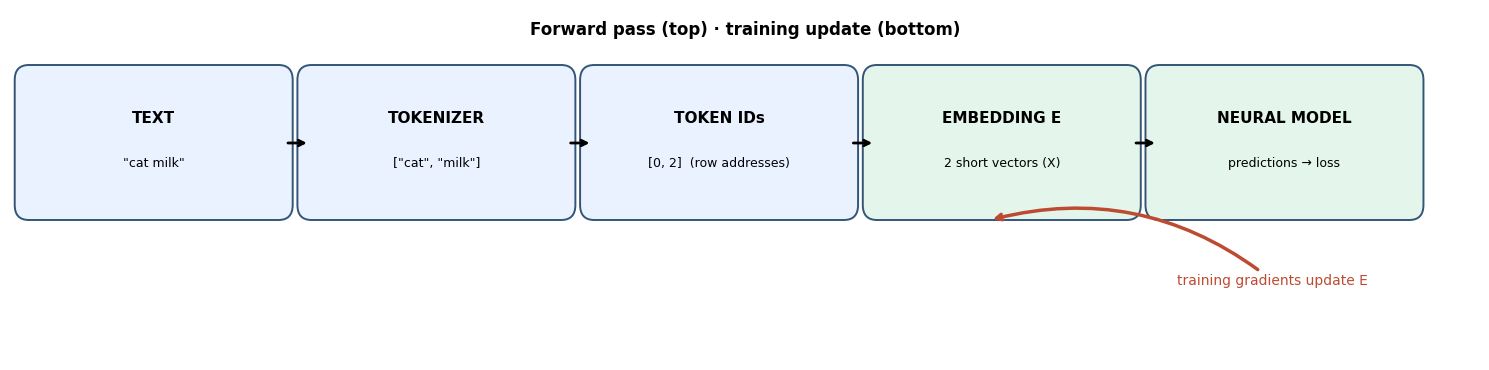

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.set_xlim(-0.2, 15.4); ax.set_ylim(-0.35, 3.15); ax.axis("off")
stages = [
    (0.0, "TEXT", '"cat milk"'),
    (3.0, "TOKENIZER", '["cat", "milk"]'),
    (6.0, "TOKEN IDs", '[0, 2]  (row addresses)'),
    (9.0, "EMBEDDING E", "2 short vectors (X)"),
    (12.0, "NEURAL MODEL", "predictions → loss"),
]
for j, (x, name, example) in enumerate(stages):
    box = FancyBboxPatch((x,1.2), 2.65, 1.25, boxstyle="round,pad=0.15", linewidth=1.4,
                         edgecolor="#335577", facecolor="#eaf2ff" if j < 3 else "#e4f6ec")
    ax.add_patch(box)
    ax.text(x+1.325, 2.02, name, weight="bold", ha="center", fontsize=11)
    ax.text(x+1.325, 1.58, example, ha="center", fontsize=9)
    if j < 4:
        ax.annotate("", xy=(x+2.98,1.82), xytext=(x+2.72,1.82), arrowprops=dict(arrowstyle="->",lw=2))
ax.annotate("training gradients update E", xy=(10.2,1.05), xytext=(13.2,0.4),
            arrowprops=dict(arrowstyle="->",color="#bd4b32",lw=2.5,connectionstyle="arc3,rad=0.25"),
            color="#bd4b32",fontsize=10,ha="center")
ax.text(7.6,2.9,"Forward pass (top) · training update (bottom)",ha="center",fontsize=12,weight="bold")
plt.tight_layout(); plt.show()

# Before attention: how does a neural network read a sentence?

Take the sentence **`cat milk`**. A neural network expects numerical tensors, not literal Python words.

1. **Tokenization:** split or encode text into *tokens* (which may be whole words, parts of words, or punctuation).
2. **Vocabulary:** assign every token in a tokenizer's vocabulary a unique integer, called its **token ID**.
3. **Embedding lookup:** use each token ID as an **index into a trainable table**, producing a short vector.

$$\text{`cat milk`} \longrightarrow [\text{`cat`},\text{`milk`}] \longrightarrow [0,2] \longrightarrow [E_0,E_2]$$

**Why do we need the ID?** It is a compact, reproducible way to tell the embedding layer **which row to retrieve**. An ID is *not a measurement*: `road = 4` does not mean road is numerically twice as meaningful as milk (`milk = 2`). Different tokenizers may assign different IDs to the same token.

In [3]:
vocab = ["cat", "dog", "milk", "car", "road"]
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}
sentence = "cat milk"
tokens_sentence = sentence.split()            # teaching example, not a production tokenizer
ids = [word_to_id[token] for token in tokens_sentence]

print("VOCABULARY (= dictionary of row addresses)")
print("  token  | token ID")
print("  -------|---------")
for token, index in word_to_id.items():
    print(f"  {token:<7}| {index}")
print("\nText:       ", repr(sentence))
print("Tokens:     ", tokens_sentence)
print("Token IDs:  ", ids)
print("Recover:    ", [id_to_word[i] for i in ids])
assert ids == [0, 2]

VOCABULARY (= dictionary of row addresses)
  token  | token ID
  -------|---------
  cat    | 0
  dog    | 1
  milk   | 2
  car    | 3
  road   | 4

Text:        'cat milk'
Tokens:      ['cat', 'milk']
Token IDs:   [0, 2]
Recover:     ['cat', 'milk']


### Token IDs are *addresses*, not learned meanings

Suppose a toy table contains three vectors. The integer `2` tells the model: *take row 2*. It does **not** tell the model that word 2 is bigger, closer, or more important than word 1.

Even if we **renumber all IDs**, embeddings stay unchanged provided we also **reorder the rows consistently**. This is a useful way to prove that the numeral itself has no semantics.

In [4]:
tiny_words = ["cat", "dog", "car"]
tiny_table = np.array([[0.9, 0.1], [0.8, 0.2], [-0.7, 0.3]])
original_ids = dict(zip(tiny_words, [0,1,2]))
renumbered_ids = {"cat": 2, "dog": 0, "car": 1}
renumbered_table = tiny_table[[1,2,0]]      # rows now [dog, car, cat]

print("Token  old ID → old lookup      new ID → new lookup")
for w in tiny_words:
    old_vec = tiny_table[original_ids[w]]
    new_vec = renumbered_table[renumbered_ids[w]]
    print(f"{w:<5}    {original_ids[w]} → {old_vec}       {renumbered_ids[w]} → {new_vec}")
    assert np.allclose(old_vec,new_vec)
print("\n✔ Renumbering IDs did not change any retrieved vector.")

Token  old ID → old lookup      new ID → new lookup
cat      0 → [0.9 0.1]       2 → [0.9 0.1]
dog      1 → [0.8 0.2]       0 → [0.8 0.2]
car      2 → [-0.7  0.3]       1 → [-0.7  0.3]

✔ Renumbering IDs did not change any retrieved vector.


## 1A. One-hot encoding: see it as a matrix (rather than a paragraph)

With **five** vocabulary tokens, a one-hot vector is a **row of the identity matrix** $I_5$.

$$
I_5=\begin{bmatrix}
1&0&0&0&0\\
0&1&0&0&0\\
0&0&1&0&0\\
0&0&0&1&0\\
0&0&0&0&1
\end{bmatrix}
\qquad \text{rows/columns: cat, dog, milk, car, road.}
$$

For example, **cat** is $[1,0,0,0,0]$ and **dog** is $[0,1,0,0,0]$.

**The limitation:** every distinct word is orthogonal to every other one: $\mathrm{cat}\cdot\mathrm{dog}=0$ and $\mathrm{cat}\cdot\mathrm{car}=0$. The one-hot representation **encodes identity but no learned similarity**. It is also extremely wide for large vocabularies.

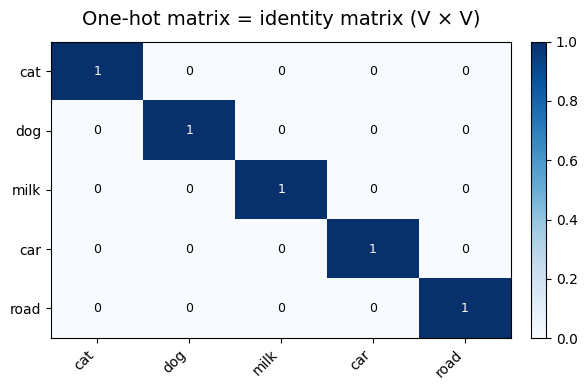

'cat' one-hot: [1 0 0 0 0]
'dog' one-hot: [0 1 0 0 0]
'car' one-hot: [0 0 0 1 0]
cat · dog = 0 ; cat · car = 0
Euclidean distances: cat↔dog = 1.414 ; cat↔car = 1.414
For a vocabulary of 50,000 tokens, each full one-hot vector needs 50,000 entries.


In [5]:
onehot_table = np.eye(len(vocab),dtype=int)
plot_heatmap(onehot_table, x_labels=vocab, y_labels=vocab,
             title="One-hot matrix = identity matrix (V × V)",fmt="d",cmap="Blues")

cat_hot, dog_hot, car_hot = (onehot_table[word_to_id[w]] for w in ["cat","dog","car"])
print("'cat' one-hot:",cat_hot)
print("'dog' one-hot:",dog_hot)
print("'car' one-hot:",car_hot)
print("cat · dog =", int(cat_hot @ dog_hot),"; cat · car =",int(cat_hot @ car_hot))
print("Euclidean distances: cat↔dog =",round(np.linalg.norm(cat_hot-dog_hot),3),
      "; cat↔car =",round(np.linalg.norm(cat_hot-car_hot),3))
print("For a vocabulary of 50,000 tokens, each full one-hot vector needs 50,000 entries.")

## 1B. Embeddings: short vectors that **can learn** useful relationships

An **embedding layer** is a trainable matrix $E\in\mathbb{R}^{V\times d}$, where $V$ is the vocabulary size and $d$ is the embedding dimension. Here **$V=5$, $d=2$**:

$$
E=\begin{array}{c|rr}
& \text{feature 1} & \text{feature 2}\\ \hline
\text{cat} & 0.90 & 0.10\\
\text{dog} & 0.85 & 0.20\\
\text{milk} & 0.45 & 0.70\\
\text{car} & -0.75 & 0.15\\
\text{road} & -0.80 & 0.30
\end{array}
$$

The picture below places each vector at its coordinates. **These numbers are hand-crafted just to illustrate similarity.** In real models, parameters typically begin from an initialization and are *updated by training*. Embedding dimensions are **not guaranteed** to correspond to interpretable features such as "animalness".

Embedding table E: rows = token IDs, columns = learned dimensions
E.shape = (5, 2)
E =
 [[ 0.9   0.1 ]
 [ 0.85  0.2 ]
 [ 0.45  0.7 ]
 [-0.75  0.15]
 [-0.8   0.3 ]]


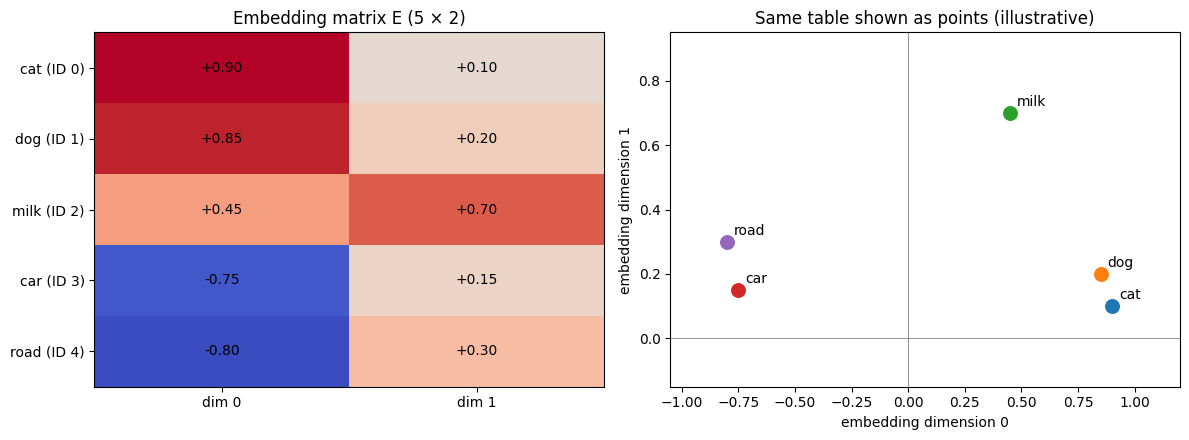

In [6]:
toy_embeddings = {
    "cat":  np.array([0.90, 0.10]),
    "dog":  np.array([0.85, 0.20]),
    "milk": np.array([0.45, 0.70]),
    "car":  np.array([-0.75, 0.15]),
    "road": np.array([-0.80, 0.30]),
}
E = np.stack([toy_embeddings[w] for w in vocab])
print("Embedding table E: rows = token IDs, columns = learned dimensions")
print("E.shape =",E.shape)
print("E =\n",E)
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
axes[0].imshow(E,aspect="auto",cmap="coolwarm")
axes[0].set_xticks(range(2),["dim 0","dim 1"])
axes[0].set_yticks(range(len(vocab)),[f"{w} (ID {word_to_id[w]})" for w in vocab])
axes[0].set_title("Embedding matrix E (5 × 2)")
for i in range(len(vocab)):
    for j in range(2):
        axes[0].text(j,i,f"{E[i,j]:+.2f}",ha="center",va="center",fontsize=10)
for word,(x,y) in toy_embeddings.items():
    axes[1].scatter(x,y,s=95)
    axes[1].annotate(word,(x,y),xytext=(5,5),textcoords="offset points")
axes[1].axvline(0,color="gray",lw=.6); axes[1].axhline(0,color="gray",lw=.6)
axes[1].set(xlabel="embedding dimension 0",ylabel="embedding dimension 1",
            title="Same table shown as points (illustrative)")
axes[1].set_xlim(-1.05,1.2);axes[1].set_ylim(-.15,.95)
plt.tight_layout();plt.show()

### One-hot and embedding lookup are mathematically connected

For token ID $i$, get its embedding by **selecting row $i$**:

$$ e_i=E[i,:]. $$

The same operation can be written as one-hot matrix multiplication:

$$\underbrace{[0\;1\;0\;0\;0]}_{1\times 5}\,\underbrace{E}_{5\times 2}
=\underbrace{[0.85\;0.20]}_{1\times 2}\quad(\text{dog}).$$

For multiple tokens, stack their one-hots into a matrix $H\in\mathbb{R}^{n\times V}$:

$$\underbrace{H}_{n\times V}\underbrace{E}_{V\times d}=
\underbrace{X}_{n\times d}. $$

**Practical point:** modern embedding layers normally look up the appropriate rows **directly**, rather than constructing a huge one-hot matrix first. The math is equivalent; direct indexing saves work.

In [7]:
word = "dog"
i = word_to_id[word]
print("Step 1: dog's token ID:",i)
print("Step 2: dog's one-hot row:",onehot_table[i])
print("Step 3: one_hot @ E:",onehot_table[i] @ E)
print("Direct embedding lookup E[ID]:",E[i])

H = onehot_table[ids]    # sentence 'cat milk' -> 2 × 5
X_lookup = E[ids]        # efficient direct lookup -> 2 × 2
X_matrix = H @ E         # mathematically equivalent -> 2 × 2
print("\nBATCH MATRIX MULTIPLICATION")
print("H.shape =",H.shape, "E.shape =",E.shape, "X.shape =",X_matrix.shape)
print("H =\n",H)
print("H @ E =\n", X_matrix)
print("E[[cat_ID, milk_ID]] =\n",X_lookup)
assert np.allclose(X_matrix,X_lookup)

Step 1: dog's token ID: 1
Step 2: dog's one-hot row: [0 1 0 0 0]
Step 3: one_hot @ E: [0.85 0.2 ]
Direct embedding lookup E[ID]: [0.85 0.2 ]

BATCH MATRIX MULTIPLICATION
H.shape = (2, 5) E.shape = (5, 2) X.shape = (2, 2)
H =
 [[1 0 0 0 0]
 [0 0 1 0 0]]
H @ E =
 [[0.9  0.1 ]
 [0.45 0.7 ]]
E[[cat_ID, milk_ID]] =
 [[0.9  0.1 ]
 [0.45 0.7 ]]


## 1C. Similarity: comparing the learned *vectors*, not the IDs

For nonzero $a,b\in\mathbb{R}^d$, **cosine similarity** is

$$\cos(a,b)=\frac{a^Tb}{\|a\|\,\|b\|}. $$

In our hand-crafted toy table, `cat` and `dog` point in a similar direction, while `cat` and `car` point in very different directions. This similarity is **deliberately designed** for the example; it does *not* arise merely from assigning token IDs.

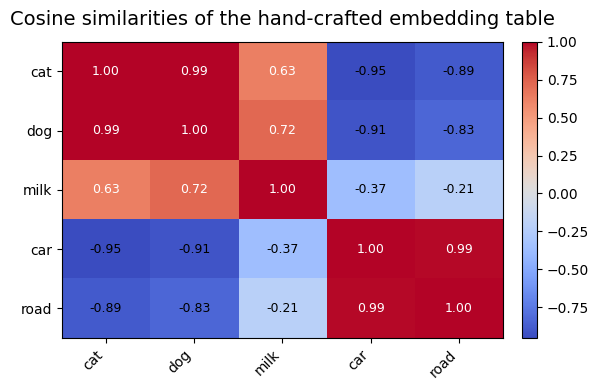

 cat vs dog : +0.993
 cat vs car : -0.953
 car vs road: +0.987
 dog vs milk: +0.719


In [8]:
def cosine_similarity(a,b):
    a,b=np.asarray(a,float),np.asarray(b,float)
    return float((a@b)/(np.linalg.norm(a)*np.linalg.norm(b)+1e-12))

sim = np.array([[cosine_similarity(E[i], E[j]) for j in range(len(vocab))]
                for i in range(len(vocab))])
plot_heatmap(sim, x_labels=vocab, y_labels=vocab,
             title="Cosine similarities of the hand-crafted embedding table",cmap="coolwarm")
for a,b in [("cat","dog"),("cat","car"),("car","road"),("dog","milk")]:
    print(f"{a:>4} vs {b:<4}: {cosine_similarity(toy_embeddings[a],toy_embeddings[b]):+.3f}")
assert cosine_similarity(E[0],E[1])>cosine_similarity(E[0],E[3])

## 1D. How does an embedding actually **learn**? One gradient update

The model **does not receive a correct embedding vector as the target**. Instead, it receives a *task*, such as **predict a label** or **predict a nearby word**, and modifies embeddings if doing so reduces prediction error.

We first use a tiny **supervised teaching task** (not Word2Vec): classify `cat/dog` as *animal*, `car/road` as *transport related*, and `milk` as *food*. This makes the gradients easy to inspect. These categories are human-provided labels; the model is not discovering them on its own.

For a token with ID $i$:

$$\begin{aligned}
\underbrace{e_i}_{1\times d}&=E[i,:],\\
\underbrace{z}_{1\times C}&=e_i\underbrace{W}_{d\times C}+b,\\
\underbrace{p}_{1\times C}&=\operatorname{softmax}(z),\\
L&=-\log p_{y}\quad\text{(cross-entropy loss)}.
\end{aligned}$$

With one-hot class target $t$, the embedding-row gradient is

$$\frac{\partial L}{\partial e_i}=W(p-t),\qquad
E[i,:]\leftarrow E[i,:]-\eta\frac{\partial L}{\partial e_i}.$$

Here vectors are treated as column vectors in the gradient formula; the code keeps embeddings as NumPy row vectors. **Watch the `cat` row change after a single step.**

Token: cat | correct teaching label: animal
Initial embedding:        [-0.1297 -0.339 ]
Classifier probabilities: [0.3803 0.2953 0.3245] → ['animal', 'transport', 'food']
Gradient dL/de:          [0.3691 0.2311]
Updated embedding:       [-0.425  -0.5239]
Cross-entropy loss: 0.9669 → 0.8230


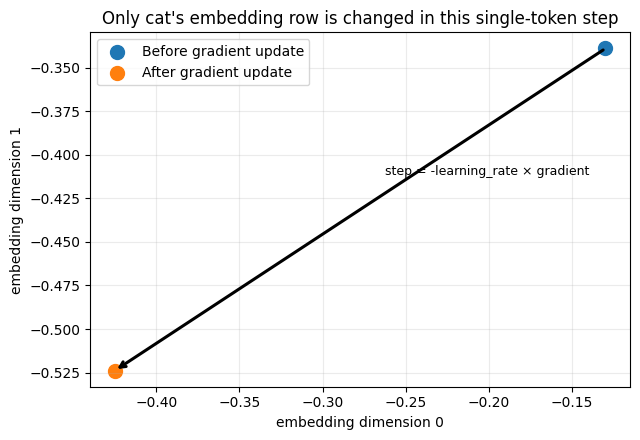

In [9]:
category_names = ["animal","transport","food"]
target_classes = np.array([0,0,2,1,1])  # cat/dog=animal, milk=food, car/road=transport
rng = np.random.default_rng(18)
E_initial = rng.normal(0,0.30,(len(vocab),2))  # randomly initialized embedding parameters
W_initial = rng.normal(0,0.35,(2,len(category_names)))
b_initial = np.zeros(len(category_names))

cat_id=word_to_id["cat"]
e_old=E_initial[cat_id].copy()
target=target_classes[cat_id]
probs_before=softmax(e_old@W_initial+b_initial)
target_onehot=np.eye(len(category_names))[target]
loss_before=-np.log(probs_before[target])
dL_de=W_initial@(probs_before-target_onehot)
eta=0.8
e_updated=e_old-eta*dL_de
probs_after=softmax(e_updated@W_initial+b_initial)
loss_after=-np.log(probs_after[target])
print("Token: cat | correct teaching label: animal")
print("Initial embedding:       ",np.round(e_old,4))
print("Classifier probabilities:",np.round(probs_before,4),"→",category_names)
print("Gradient dL/de:         ",np.round(dL_de,4))
print("Updated embedding:      ",np.round(e_updated,4))
print(f"Cross-entropy loss: {loss_before:.4f} → {loss_after:.4f}")
assert loss_after < loss_before

fig,ax=plt.subplots(figsize=(6.5,4.5))
ax.scatter(*e_old,s=100,label="Before gradient update")
ax.scatter(*e_updated,s=100,label="After gradient update")
ax.annotate("",xy=e_updated,xytext=e_old,arrowprops=dict(arrowstyle="->",lw=2.2,color="black"))
ax.annotate("step = -learning_rate × gradient", xy=(e_old+e_updated)/2,xytext=(18,25),
            textcoords="offset points",fontsize=9)
ax.set(xlabel="embedding dimension 0",ylabel="embedding dimension 1",
       title="Only cat's embedding row is changed in this single-token step")
ax.legend();ax.grid(alpha=.25);plt.tight_layout();plt.show()

### Repeat training: the prediction loss reshapes the embedding space

Now train **all five tokens** for 600 updates with ordinary full-batch gradient descent. In this simple model, both the embedding table $E$ and classifier weights $W,b$ are trained.

For $N$ training items, $P=\operatorname{softmax}(EW+b)$ and $Y$ is the $N\times C$ one-hot label matrix:

$$\begin{aligned}
L&=-\frac{1}{N}\sum_{i=1}^{N}\log P_{i,y_i},\\
D&=\frac{P-Y}{N},\\
\nabla_E L&=DW^T,\quad \nabla_W L=E^TD,\quad\nabla_b L=\sum_iD_i.
\end{aligned}$$

**No neural network layer “knows” that cat resembles dog beforehand**. The similarity below emerges from these specific training labels and the optimization process. With different data or objectives the geometry might change.

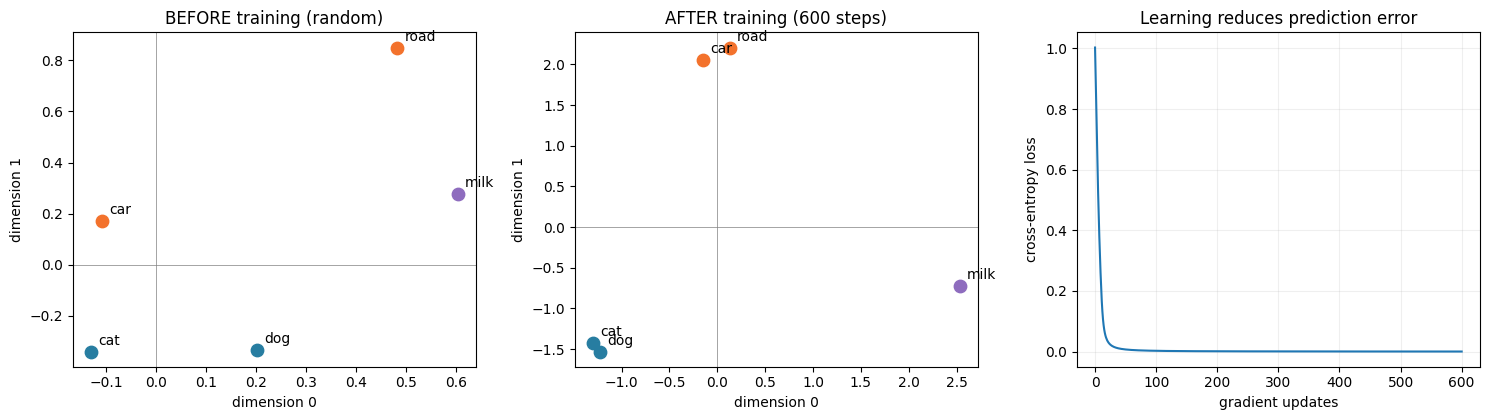

Final predictions (model trained on all five teaching examples):
  cat   → animal     (p=1.000)
  dog   → animal     (p=1.000)
  milk  → food       (p=1.000)
  car   → transport  (p=1.000)
  road  → transport  (p=1.000)

cat–dog cosine: before 0.612 after 0.998
car–road cosine: before 0.472 after 0.991


In [10]:
E_learned=E_initial.copy()
W_learned=W_initial.copy()
b_learned=b_initial.copy()
Y=np.eye(len(category_names))[target_classes]
loss_history=[]
for step in range(601):
    logits=E_learned@W_learned+b_learned
    P=softmax(logits,axis=1)
    loss=-np.mean(np.log(P[np.arange(len(vocab)),target_classes]+1e-12))
    loss_history.append(loss)
    if step==600: break
    D=(P-Y)/len(vocab)
    grad_E=D@W_learned.T
    grad_W=E_learned.T@D
    grad_b=D.sum(axis=0)
    lr=1.0
    E_learned-=lr*grad_E
    W_learned-=lr*grad_W
    b_learned-=lr*grad_b

fig,axes=plt.subplots(1,3,figsize=(15,4.3))
for ax, table, title in zip(axes[:2],[E_initial,E_learned],
                            ["BEFORE training (random)","AFTER training (600 steps)"]):
    for w in vocab:
        xy=table[word_to_id[w]]
        class_id=target_classes[word_to_id[w]]
        ax.scatter(*xy,color=["#277da1","#f3722c","#8e6cbe"][class_id],s=80)
        ax.annotate(w,xy,xytext=(5,5),textcoords="offset points")
    ax.set(xlabel="dimension 0",ylabel="dimension 1",title=title)
    ax.axhline(0,color="gray",lw=.5);ax.axvline(0,color="gray",lw=.5)
axes[2].plot(loss_history)
axes[2].set(xlabel="gradient updates",ylabel="cross-entropy loss",title="Learning reduces prediction error")
axes[2].grid(alpha=.2)
plt.tight_layout();plt.show()
print("Final predictions (model trained on all five teaching examples):")
for i,w in enumerate(vocab):
    predicted=category_names[P[i].argmax()]
    print(f"  {w:<5} → {predicted:<10} (p={P[i].max():.3f})")
print("\ncat–dog cosine: before",
      round(cosine_similarity(E_initial[0],E_initial[1]),3),"after",
      round(cosine_similarity(E_learned[0],E_learned[1]),3))
print("car–road cosine: before",
      round(cosine_similarity(E_initial[3],E_initial[4]),3),"after",
      round(cosine_similarity(E_learned[3],E_learned[4]),3))
assert loss_history[-1] < loss_history[0]

### What does the embedding "learn"? Three important distinctions

| Part | Fixed or learned? | Role |
|---|---|---|
| **Tokenizer + token IDs** | Usually fixed while training the neural network | Defines *which row* is retrieved |
| **Embedding matrix $E$** | **Learned** parameters | Learns feature vectors useful for the task |
| **Classifier/attention/other model weights** | **Learned** parameters | Turn vectors into predictions, and propagate error back to $E$ |

What may appear in a good embedding space? **Statistical patterns** such as related usage, similar contexts, syntax, or task-relevant distinctions. What is *not* guaranteed? That dimension 0 literally means “animal”, that every nearby vector has the same meaning, or that an embedding alone resolves word sense.

**Checkpoint:** Why does changing the **loss or task** change what the embedding table learns?

## 1E. Word2Vec-style context learning: **no manual animal labels**

In real language representation learning, one option is to train vectors from the **text context itself**, rather than labels like “animal”. For the classic **skip-gram** idea, a **center token** is used to predict a nearby **context token**.

For example, `the cat drinks milk` supplies `(cat → the)` and `(cat → drinks)` for a window of one position. Below we generate training pairs and then **actually train** a tiny *full-softmax skip-gram* model.

**Two parameter tables:** input embeddings $U\in\mathbb{R}^{V\times d}$ and output embeddings $O\in\mathbb{R}^{V\times d}$. For center $c$ and context $o$:

$$z_j=U_c\cdot O_j,\quad p(j\mid c)=\frac{e^{z_j}}{\sum_k e^{z_k}},\quad L=-\log p(o\mid c).$$

The loss updates **$U_c$ and the output table $O$**. In large-scale Word2Vec, training may instead use negative sampling or hierarchical softmax; this example deliberately uses the transparent full softmax.

In [11]:
tiny_corpus=["the cat drinks milk","the dog drinks water","the car uses road"]
window=1
pairs=[]
for sentence_text in tiny_corpus:
    wds=sentence_text.split()
    for i,center in enumerate(wds):
        for j in range(max(0,i-window),min(len(wds),i+window+1)):
            if i!=j: pairs.append((center,wds[j]))
print("Text lines:")
for sentence_text in tiny_corpus: print("  ",sentence_text)
print("\nFirst 12 center → context pairs:")
for center,context in pairs[:12]: print(f"  {center:<8} → {context}")
print("Total training pairs:",len(pairs))

Text lines:
   the cat drinks milk
   the dog drinks water
   the car uses road

First 12 center → context pairs:
  the      → cat
  cat      → the
  cat      → drinks
  drinks   → cat
  drinks   → milk
  milk     → drinks
  the      → dog
  dog      → the
  dog      → drinks
  drinks   → dog
  drinks   → water
  water    → drinks
Total training pairs: 18


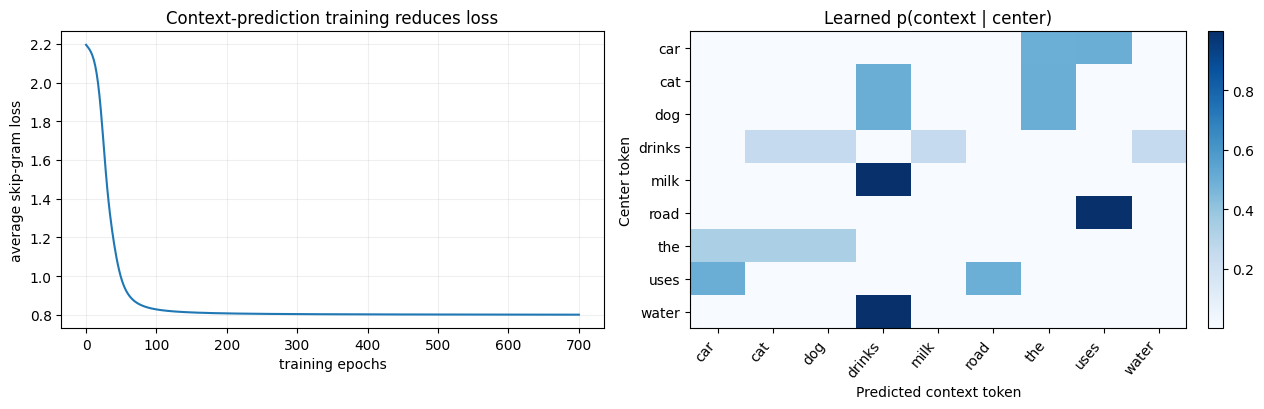

center 'cat' predicts: [('drinks', 0.5), ('the', 0.499), ('uses', 0.0)]
center 'dog' predicts: [('drinks', 0.5), ('the', 0.499), ('uses', 0.0)]
center 'car' predicts: [('uses', 0.499), ('the', 0.499), ('drinks', 0.001)]

This tiny corpus is insufficient for strong semantic claims; it only demonstrates learning from context.


In [12]:
# Minimal Word2Vec-style full-softmax training. No deep-learning framework needed.
skip_vocab=sorted(set(word for p in pairs for word in p))
skip_id={w:i for i,w in enumerate(skip_vocab)}
center_ids=np.array([skip_id[a] for a,b in pairs])
context_ids=np.array([skip_id[b] for a,b in pairs])
V_skip=len(skip_vocab); d_skip=4
rng=np.random.default_rng(7)
U=rng.normal(0,0.15,size=(V_skip,d_skip))  # input embeddings (learned)
O=rng.normal(0,0.15,size=(V_skip,d_skip))  # output embeddings (learned)
sg_losses=[]
for epoch in range(701):
    z=U[center_ids]@O.T
    probs=softmax(z,axis=1)
    sg_loss=-np.mean(np.log(probs[np.arange(len(pairs)),context_ids]+1e-12))
    sg_losses.append(sg_loss)
    if epoch==700: break
    dz=probs.copy()
    dz[np.arange(len(pairs)),context_ids]-=1
    dz/=len(pairs)
    dU_selected=dz@O
    dO=dz.T@U[center_ids]
    dU=np.zeros_like(U)
    np.add.at(dU,center_ids,dU_selected)       # accumulate repeated center-token gradients
    rate=0.8
    U-=rate*dU
    O-=rate*dO

fig,axes=plt.subplots(1,2,figsize=(12.8,4.2))
axes[0].plot(sg_losses);axes[0].set(xlabel="training epochs",ylabel="average skip-gram loss",
                                  title="Context-prediction training reduces loss")
axes[0].grid(alpha=.2)
context_probabilities=softmax(U@O.T,axis=1)
im=axes[1].imshow(context_probabilities,aspect="auto",cmap="Blues")
axes[1].set_xticks(range(V_skip),skip_vocab,rotation=50,ha="right")
axes[1].set_yticks(range(V_skip),skip_vocab)
axes[1].set(xlabel="Predicted context token",ylabel="Center token",
            title="Learned p(context | center)")
fig.colorbar(im,ax=axes[1],fraction=.045,pad=.04)
plt.tight_layout();plt.show()
for center in ["cat","dog","car"]:
    p=context_probabilities[skip_id[center]]
    top=np.argsort(p)[-3:][::-1]
    print(f"center '{center}' predicts:",[(skip_vocab[j],round(float(p[j]),3)) for j in top])
print("\nThis tiny corpus is insufficient for strong semantic claims; it only demonstrates learning from context.")
assert sg_losses[-1] < sg_losses[0]

### A bridge to language models and Transformers

A Transformer often starts with the same basic **embedding lookup** $X=E[\mathrm{IDs}]$; then positions and attention let it construct **contextual token representations**. During language-model training, errors in a prediction objective (such as next-token prediction) backpropagate through the model to update the embedding weights as well as attention/other weights.

$$\boxed{\text{token IDs}}\xrightarrow{\text{lookup }E}
\boxed{X}\xrightarrow{\text{attention + neural layers}}
\boxed{\text{predictions}}\xrightarrow{\text{loss}}
\boxed{\text{gradients into }E\text{ and other weights}}$$

**Remember:** a context-trained *static* word embedding (e.g. simple Word2Vec) gives the same base vector to a word each time; a Transformer can give it **different contextual outputs** depending on the sentence.

## 1F. Why modern tokenizers often split into subwords

With a word-only vocabulary, a new or rare word may be out of vocabulary. Subword tokenization reuses common pieces. Examples **below are manually chosen splits**, not an actual BPE tokenizer's output. Once the pieces have IDs, **each piece gets its own embedding lookup**.

$$\text{`unhappiness`}\ \longrightarrow\ [\text{`un`},\text{`happy`},\text{`ness`}]
\ \longrightarrow\ [i,j,k]\ \longrightarrow\ [E_i,E_j,E_k].$$

**BPE**, **WordPiece**, and **Unigram** are examples of subword segmentation approaches (with implementation differences). Modern tokenization can be more nuanced than simply splitting by spaces.

In [13]:
examples = {
    "playing": ["play", "ing"],
    "unhappiness": ["un", "happy", "ness"],
    "redoing": ["re", "do", "ing"],
}
for text, pieces in examples.items():
    print(f"{text:<13} -> {pieces}  (illustrative segmentation)")
print("Caution: this is NOT the output of an actual BPE tokenizer.")

playing       -> ['play', 'ing']  (illustrative segmentation)
unhappiness   -> ['un', 'happy', 'ness']  (illustrative segmentation)
redoing       -> ['re', 'do', 'ing']  (illustrative segmentation)
Caution: this is NOT the output of an actual BPE tokenizer.


## 1G. Static versus contextual representations: why attention comes next

A *static* lookup gives the same base vector to `bank` in both:

- **I deposited money at the bank.**
- **We sat by the river bank.**

But context changes the meaning. A **contextual model** uses other tokens to build a *different output representation* for each occurrence of `bank`. Self-attention is one mechanism for doing that. It is not that a word embedding magically learns the correct sense from an isolated token ID.

**Quick oral check:** What is the difference between $E[\text{bank\_ID}]$ and a Transformer's context-dependent representation of `bank` in a particular sentence?

# 1. Why do we need attention?

Early sequence-to-sequence models usually compressed the entire input sentence into **one fixed-size context vector**.

That creates a bottleneck.

Example:

```text
Input:  hum baazaar gaye the
Output: we went to the market
```

If the whole Hindi sentence is compressed into one vector, the decoder may lose details such as:

- which word means "market"
- which word carries tense information
- which source word matters for the current output word

Attention solves this by allowing the decoder to look back at **all encoder states**, not just one final vector.

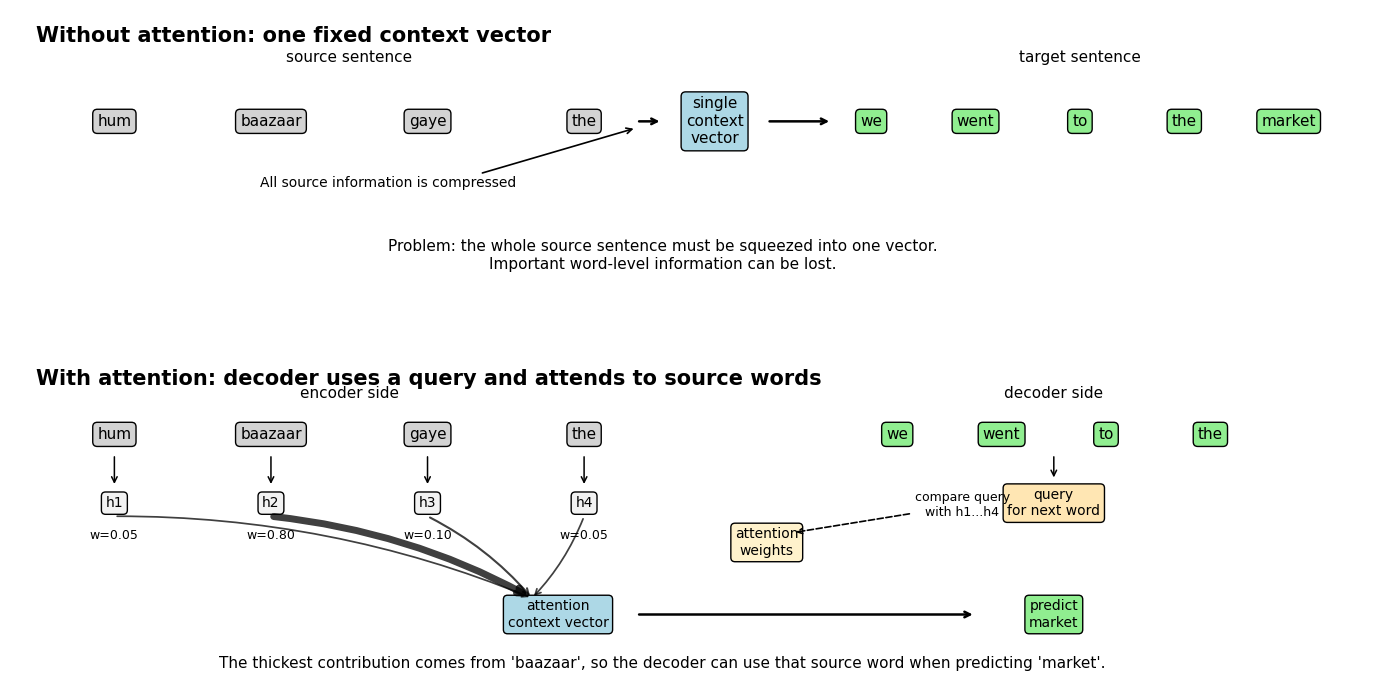

In [14]:
# @title
# visual diagram: without attention vs with attention
# This diagram is intentionally simple for teaching.
# It shows the missing pieces: encoder states, decoder query, attention weights, and context vector.

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

source_tokens = ["hum", "baazaar", "gaye", "the"]
target_tokens = ["we", "went", "to", "the", "market"]
source_x = [0.08, 0.20, 0.32, 0.44]
target_x = [0.66, 0.74, 0.82, 0.90, 0.98]

def box(ax, x, y, text, color, fontsize=11):
    ax.text(
        x, y, text,
        ha="center", va="center", fontsize=fontsize,
        bbox=dict(boxstyle="round,pad=0.3", fc=color, ec="black", lw=1)
    )

def setup_axis(ax, title):
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.text(0.02, 0.92, title, fontsize=15, weight="bold", ha="left", va="center")

# -------------------- Without attention --------------------
ax = axes[0]
setup_axis(ax, "Without attention: one fixed context vector")

ax.text(0.26, 0.84, "source sentence", fontsize=11, ha="center")
for x, tok in zip(source_x, source_tokens):
    box(ax, x, 0.66, tok, "lightgray")

box(ax, 0.54, 0.66, "single\ncontext\nvector", "lightblue")

ax.text(0.82, 0.84, "target sentence", fontsize=11, ha="center")
for x, tok in zip(target_x, target_tokens):
    box(ax, x, 0.66, tok, "lightgreen")

# One clean arrow from source group to context vector, then to target group
ax.annotate(
    "", xy=(0.50, 0.66), xytext=(0.48, 0.66),
    arrowprops=dict(arrowstyle="->", lw=1.8)
)
ax.annotate(
    "", xy=(0.63, 0.66), xytext=(0.58, 0.66),
    arrowprops=dict(arrowstyle="->", lw=1.8)
)
ax.text(
    0.29, 0.46, "All source information is compressed", fontsize=10, ha="center"
)
ax.annotate(
    "", xy=(0.48, 0.64), xytext=(0.36, 0.50),
    arrowprops=dict(arrowstyle="->", lw=1.2)
)
ax.text(
    0.50, 0.25,
    "Problem: the whole source sentence must be squeezed into one vector.\nImportant word-level information can be lost.",
    ha="center", va="center", fontsize=11
)

# -------------------- With attention --------------------
ax = axes[1]
setup_axis(ax, "With attention: decoder uses a query and attends to source words")

# Source tokens and encoder states
ax.text(0.26, 0.86, "encoder side", fontsize=11, ha="center")
for i, (x, tok) in enumerate(zip(source_x, source_tokens), start=1):
    box(ax, x, 0.75, tok, "lightgray")
    box(ax, x, 0.54, f"h{i}", "#f2f2f2", fontsize=10)
    ax.annotate(
        "", xy=(x, 0.59), xytext=(x, 0.69),
        arrowprops=dict(arrowstyle="->", lw=1.1)
    )

# Decoder side: previous words produce a query for the next word
ax.text(0.80, 0.86, "decoder side", fontsize=11, ha="center")
prev_x = [0.68, 0.76, 0.84, 0.92]
prev_words = ["we", "went", "to", "the"]
for x, tok in zip(prev_x, prev_words):
    box(ax, x, 0.75, tok, "lightgreen")

box(ax, 0.80, 0.54, "query\nfor next word", "#ffe6b3", fontsize=10)
ax.annotate(
    "", xy=(0.80, 0.61), xytext=(0.80, 0.69),
    arrowprops=dict(arrowstyle="->", lw=1.1)
)

# Attention weights are produced by comparing decoder query with encoder states
box(ax, 0.58, 0.42, "attention\nweights", "#fff2cc", fontsize=10)
ax.annotate(
    "compare query\nwith h1...h4", xy=(0.60, 0.45), xytext=(0.73, 0.50),
    fontsize=9, ha="center",
    arrowprops=dict(arrowstyle="->", lw=1.2, linestyle="--")
)

# Context vector and prediction
box(ax, 0.42, 0.20, "attention\ncontext vector", "lightblue", fontsize=10)
box(ax, 0.80, 0.20, "predict\nmarket", "lightgreen", fontsize=10)
ax.annotate(
    "", xy=(0.74, 0.20), xytext=(0.48, 0.20),
    arrowprops=dict(arrowstyle="->", lw=1.8)
)

# Weighted contribution arrows from encoder states to context vector
weights = [0.05, 0.80, 0.10, 0.05]
for x, tok, w in zip(source_x, source_tokens, weights):
    lw = 1.0 + 5.0 * w
    ax.text(x, 0.43, f"w={w:.2f}", fontsize=9, ha="center")
    ax.annotate(
        "", xy=(0.40, 0.25), xytext=(x, 0.50),
        arrowprops=dict(
            arrowstyle="->", lw=lw, alpha=0.75,
            connectionstyle="arc3,rad=-0.10"
        )
    )

ax.text(
    0.50, 0.05,
    "The thickest contribution comes from 'baazaar', so the decoder can use that source word when predicting 'market'.",
    ha="center", va="center", fontsize=11
)

plt.tight_layout()
plt.show()




**Question:** Why is a single context vector a bottleneck?

**answer:**  
Because one vector must store information about the entire input sequence. For long sentences, important details may be compressed or lost. Attention lets the decoder access all encoder outputs directly.

## Bridge: From sequential models to attention

**Why RNNs?** Word order matters, so an RNN processes token embeddings step by step and updates a hidden state. An early RNN encoder–decoder often passed its final hidden state to the decoder as a fixed-size summary. **Why attention next?** The decoder could benefit from accessing *all* encoder states rather than relying only on one summary.

**Caveat:** This is a conceptual motivation, not a claim that RNNs can never process long sentences. LSTMs/GRUs help, but long-range dependencies remain challenging.

In [15]:
# A tangible fixed-summary example: different sentences, same simple mean summary.
# This mean is NOT an actual RNN hidden state; it only illustrates information loss.
a = np.array([[1.,0.],[0.,1.]])  # "dog bites"
b = np.array([[0.,1.],[1.,0.]])  # "bites dog"
print("Order A:", a.tolist(), "mean:", a.mean(axis=0))
print("Order B:", b.tolist(), "mean:", b.mean(axis=0))
print("Averages match despite different order! Real encoder states can encode order, but fixed summaries can bottleneck information.")

Order A: [[1.0, 0.0], [0.0, 1.0]] mean: [0.5 0.5]
Order B: [[0.0, 1.0], [1.0, 0.0]] mean: [0.5 0.5]
Averages match despite different order! Real encoder states can encode order, but fixed summaries can bottleneck information.


# 2. Warm-up: scores become probabilities using softmax

Attention begins with a set of **scores**.

A high score means:  
> "This token is relevant."

Then softmax converts scores into **attention weights**.

Properties of attention weights:

1. Every weight is between 0 and 1.
2. The weights in one row sum to 1.
3. Higher score usually means higher attention weight.

Scores: [0.2 2.5 0.7 0.1]
Attention weights: [0.074 0.737 0.122 0.067]
Sum of weights: 1.0


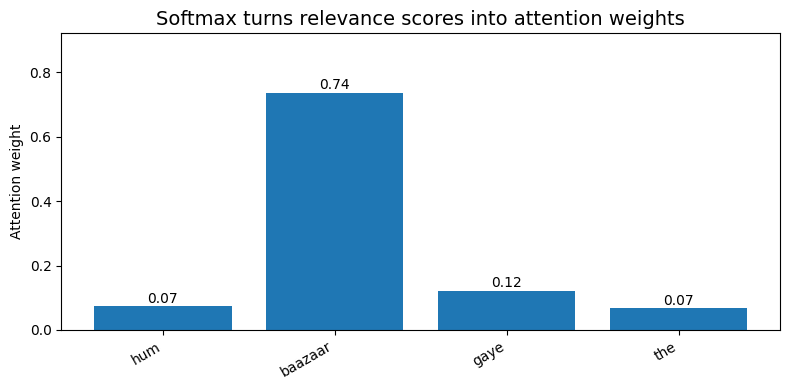

In [16]:
words = ["hum", "baazaar", "gaye", "the"]
scores = np.array([0.2, 2.5, 0.7, 0.1])
weights = softmax(scores)

print("Scores:", scores)
print("Attention weights:", np.round(weights, 3))
print("Sum of weights:", np.round(weights.sum()))

plot_bar(words, weights, title="Softmax turns relevance scores into attention weights", ylabel="Attention weight")

Notice that **baazaar** receives the highest weight because it has the highest score.

This is the core idea:

```text
attention output = weighted average of value vectors
```

### Softmax: calculate it yourself

Suppose similarity scores are $[2,1,0]$. First exponentiate each score, then divide by the sum of exponentials. The largest score gets the highest weight, but other positions can still contribute.

**Question:** Do these weights tell us the probability a word is *correct*? **No:** they are a normalized distribution for mixing value vectors, not calibrated confidence in a prediction.

In [17]:
small_scores = np.array([2.,1.,0.])
exp_scores = np.exp(small_scores)
manual_weights = exp_scores / exp_scores.sum()
print("scores       :", small_scores)
print("exp(scores)  :", np.round(exp_scores,3))
print("sum exp      :", round(exp_scores.sum(),3))
print("softmax      :", np.round(manual_weights,3))
assert np.allclose(manual_weights, softmax(small_scores))

scores       : [2. 1. 0.]
exp(scores)  : [7.389 2.718 1.   ]
sum exp      : 11.107
softmax      : [0.665 0.245 0.09 ]


# 3. Cross-attention in a sequence-to-sequence model

In translation, the decoder produces one target word at a time.

For each target word, it attends to the source words.

Example:

```text
Source: hum baazaar gaye the
Target: we went to the market
```

A useful attention pattern might look like this:

- "we" attends to "hum"
- "went" attends to "gaye"
- "market" attends to "baazaar"
- "the" may attend to context words

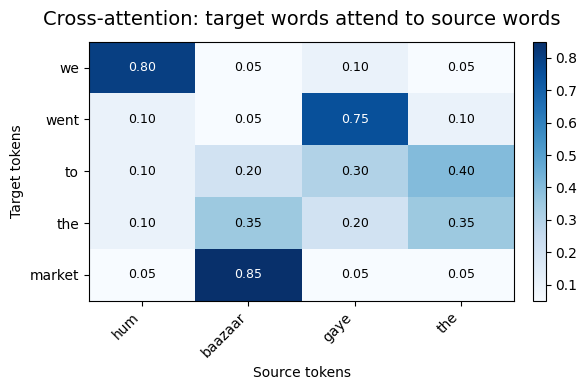

Each row sums to: [1. 1. 1. 1. 1.]


In [18]:
source = ["hum", "baazaar", "gaye", "the"]
target = ["we", "went", "to", "the", "market"]

# A hand-crafted attention matrix.
# Rows = target tokens, columns = source tokens.
cross_attention = np.array([
    [0.80, 0.05, 0.10, 0.05],  # we -> hum
    [0.10, 0.05, 0.75, 0.10],  # went -> gaye
    [0.10, 0.20, 0.30, 0.40],  # to -> function/context
    [0.10, 0.35, 0.20, 0.35],  # the -> context
    [0.05, 0.85, 0.05, 0.05],  # market -> baazaar
])

plot_heatmap(
    cross_attention,
    x_labels=source,
    y_labels=target,
    title="Cross-attention: target words attend to source words",
    xlabel="Source tokens",
    ylabel="Target tokens",
    cmap="Blues"
)

print("Each row sums to:", np.round(cross_attention.sum(axis=1), 3))

## Important interpretation

A row tells us:

> For this target token, how much attention is paid to each source token?

For example, the row for **market** has high attention on **baazaar**.

Attention weights can give a rough idea of which tokens the model is focusing on, but they are **not always a perfect explanation** of the model's decision.



**Question:** In the heatmap above, why does "market" attend strongly to "baazaar"?

**answer:**  
Because "baazaar" carries the meaning of "market", so it is the most relevant source token when producing the target token "market".

### Why does Q/K/V help? A practical retrieval analogy

You search a library: **query** = what you need; **keys** = labels used to match; **values** = actual information returned. A query is compared with all keys; the resulting weights mix the values.

**Important distinction:** keys are used to compute *where to look*; values supply *what to take*. The same underlying token representations can produce different learned Q, K, and V projections.

# 4. Query, Key, and Value: the retrieval view

Attention can be understood like searching in a library.

| Component | Meaning | Simple analogy |
|---|---|---|
| Query | What I am looking for | A search query |
| Key | What each item offers | Book index/card |
| Value | The actual information | Book content |

The attention process is:

1. Compare the **query** with all **keys**.
2. Convert similarities into weights using softmax.
3. Take a weighted average of **values**.

## Scaled Dot-Product Attention: Formula and Shapes

Mathematically, scaled dot-product attention is written as:

$$
\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

Where:

- **Q** = Query matrix  
- **K** = Key matrix  
- **V** = Value matrix  
- **d_k** = dimension of each key/query vector  




---

### Intuition

The matrix:

$$
QK^T
$$

tells us how much each query should attend to each key.

The softmax converts these scores into attention weights.

Then multiplying by:

$$
V
$$

creates the final output as a weighted combination of value vectors.

In [19]:

### 2. Code cell: realistic Q, K, V example

import numpy as np
import matplotlib.pyplot as plt

def softmax(x, axis=-1):
    exp_x = np.exp(x - np.max(x, axis=axis, keepdims=True))
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

# -----------------------------
# Realistic toy example
# -----------------------------
# Feature 1 = place-related information
# Feature 2 = action-related information

query_labels = ["predicting 'market'", "predicting 'went'"]
key_labels = ["baazaar\n(place)", "gaye\n(action)", "mixed\n(context)"]

Q = np.array([
    [1.0, 0.0],   # Query 1: predicting "market", looking for place
    [0.0, 1.0],   # Query 2: predicting "went", looking for action
])

K = np.array([
    [1.0, 0.0],   # Key A: "baazaar", place-related
    [0.0, 1.0],   # Key B: "gaye", action-related
    [0.7, 0.7],   # Key C: mixed context
])

V = np.array([
    [10.0, 0.0],  # Value A: information from "baazaar"
    [0.0, 10.0],  # Value B: information from "gaye"
    [5.0, 5.0],   # Value C: mixed information
])

d_k = Q.shape[1]

scores = Q @ K.T
scaled_scores = scores / np.sqrt(d_k)
attention_weights = softmax(scaled_scores, axis=-1)
output = attention_weights @ V


print("\nRaw scores = Q @ K.T")
print(np.round(scores, 2))

print("\nScaled scores = scores / sqrt(d_k)")
print(np.round(scaled_scores, 2))

print("\nAttention weights after softmax:")
print(np.round(attention_weights, 3))

print("\nFinal output = attention_weights @ V")
print(np.round(output, 2))


Raw scores = Q @ K.T
[[1.  0.  0.7]
 [0.  1.  0.7]]

Scaled scores = scores / sqrt(d_k)
[[0.71 0.   0.49]
 [0.   0.71 0.49]]

Attention weights after softmax:
[[0.434 0.214 0.351]
 [0.214 0.434 0.351]]

Final output = attention_weights @ V
[[6.1 3.9]
 [3.9 6.1]]


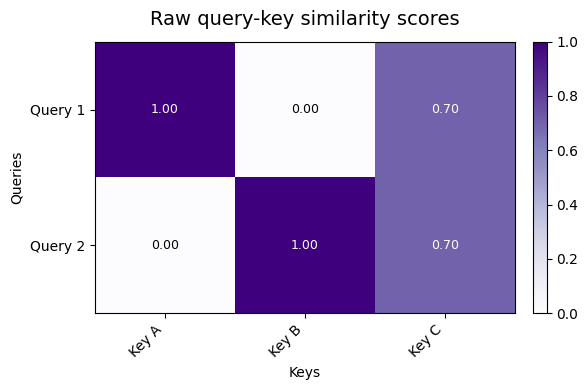

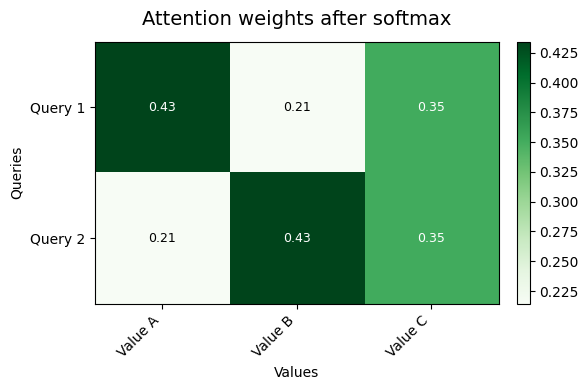

In [20]:
plot_heatmap(scores, x_labels=["Key A", "Key B", "Key C"], y_labels=["Query 1", "Query 2"],
             title="Raw query-key similarity scores", xlabel="Keys", ylabel="Queries", cmap="Purples")

plot_heatmap(attention_weights, x_labels=["Value A", "Value B", "Value C"], y_labels=["Query 1", "Query 2"],
             title="Attention weights after softmax", xlabel="Values", ylabel="Queries", cmap="Greens")

## What happened?

- Query 1 is close to Key A, so it takes more from Value A.
- Query 2 is close to Key B, so it takes more from Value B.
- Key C is mixed, so it contributes somewhat to both.

This is the complete mechanism behind scaled dot-product attention.

### One-query, two-key numeric exercise (do before self-attention)

Let $Q=[1,0]$, $K_1=[1,0]$, $K_2=[0,1]$, $V_1=[10,0]$, $V_2=[0,20]$. Find the two scores, convert to weights, then compute the output. We include the usual $1/\sqrt{2}$ scaling. Ask students to solve first.

In [21]:
q = np.array([[1.,0.]])
k = np.array([[1.,0.],[0.,1.]])
v = np.array([[10.,0.],[0.,20.]])
s = (q @ k.T) / np.sqrt(2)
w = softmax(s)
out_demo = w @ v
print("scaled scores:", np.round(s,3))
print("attention weights:", np.round(w,3))
print("weighted output:", np.round(out_demo,3))
assert out_demo.shape == (1,2)

scaled scores: [[0.707 0.   ]]
attention weights: [[0.67 0.33]]
weighted output: [[6.698 6.605]]


# 5. Self-attention

In **self-attention**, the queries, keys, and values all come from the **same sentence**.

That means every token can look at every other token.

Example sentence:

```text
the cat sat on the mat
```

Each word creates:

- a query: what information this word needs
- a key: what information this word can provide
- a value: the actual content this word contributes

Self-attention lets each token build a richer representation using context from the whole sentence.

Token embedding matrix X shape: (6, 4)
Rows = tokens, columns = features
[[0.05 0.   0.05 1.  ]
 [1.   0.1  0.   0.  ]
 [0.1  1.   0.1  0.  ]
 [0.   0.3  0.5  0.8 ]
 [0.05 0.   0.05 1.  ]
 [0.1  0.   1.   0.  ]]


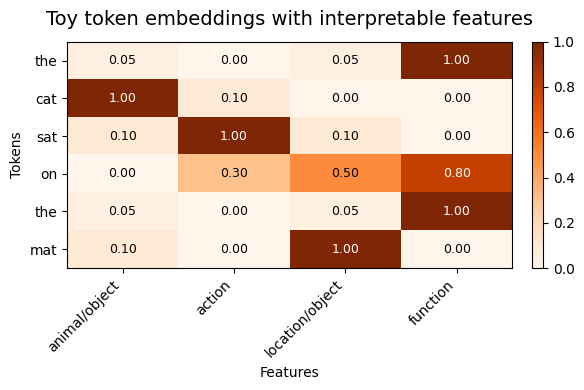

In [22]:
tokens = ["the", "cat", "sat", "on", "the", "mat"]

# For teaching, we create simple interpretable token features.
# Dimensions roughly mean: [animal/object, action, location/object, function-word]
base_vectors = {
    "the": np.array([0.05, 0.00, 0.05, 1.00]),
    "cat": np.array([1.00, 0.10, 0.00, 0.00]),
    "sat": np.array([0.10, 1.00, 0.10, 0.00]),
    "on":  np.array([0.00, 0.30, 0.50, 0.80]),
    "mat": np.array([0.10, 0.00, 1.00, 0.00]),
}

X = np.vstack([base_vectors[t] for t in tokens])

print("Token embedding matrix X shape:", X.shape)
print("Rows = tokens, columns = features")
print(np.round(X, 2))

plot_heatmap(
    X,
    x_labels=["animal/object", "action", "location/object", "function"],
    y_labels=tokens,
    title="Toy token embeddings with interpretable features",
    xlabel="Features",
    ylabel="Tokens",
    cmap="Oranges"
)

For a simple first version, let us set:

$$
Q = X,\quad K = X,\quad V = X
$$


In real Transformers, \(Q\), \(K\), and \(V\) are learned linear projections of \(X\).  


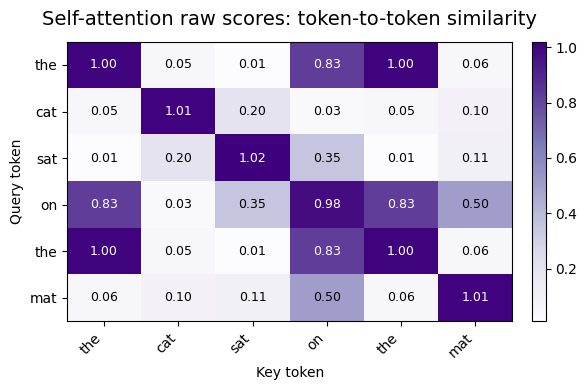

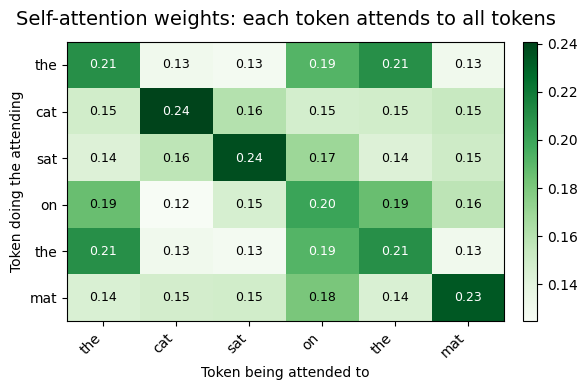

Context vectors shape: (6, 4)
[[0.177 0.198 0.26  0.573]
 [0.287 0.229 0.258 0.416]
 [0.21  0.304 0.273 0.422]
 [0.174 0.219 0.291 0.531]
 [0.177 0.198 0.26  0.573]
 [0.201 0.218 0.353 0.434]]


In [23]:
Q = X
K = X
V = X

d_k = Q.shape[1]
scores = Q @ K.T
scaled_scores = scores / np.sqrt(d_k)
self_attention_weights = softmax(scaled_scores, axis=-1)
context_vectors = self_attention_weights @ V

plot_heatmap(
    scores,
    x_labels=tokens,
    y_labels=tokens,
    title="Self-attention raw scores: token-to-token similarity",
    xlabel="Key token",
    ylabel="Query token",
    cmap="Purples"
)

plot_heatmap(
    self_attention_weights,
    x_labels=tokens,
    y_labels=tokens,
    title="Self-attention weights: each token attends to all tokens",
    xlabel="Token being attended to",
    ylabel="Token doing the attending",
    cmap="Greens"
)

print("Context vectors shape:", context_vectors.shape)
print(np.round(context_vectors, 3))

## How to read the self-attention heatmap

Rows are **query tokens**.  
Columns are **key/value tokens**.

For example:

- The row for **cat** tells us where "cat" looks.
- The row for **mat** tells us where "mat" looks.
- A bright cell means strong attention.

The output for each token is a weighted average of the value vectors.



**Question:** In self-attention, why can the representation of "cat" contain information from "sat" or "mat"?

**answer:**  
Because "cat" produces a query that is compared with all keys in the sentence. Its final context vector is a weighted average of all value vectors, so information from other tokens can be mixed into the representation of "cat".

### Where exactly do Q, K and V come from?

We first look up token vectors in the embedding table: $X\in\mathbb{R}^{n\times d_{model}}$. A Transformer learns parameter matrices $W_Q,W_K,W_V$ such that $Q=XW_Q$, $K=XW_K$, $V=XW_V$.

The earlier $Q=K=V=X$ example intentionally *skips the learned projections* so students can inspect the math. It is not the general architecture.

In [24]:
X_demo = np.array([[1.,0.],[0.,1.],[1.,1.]])
WQ = np.array([[1.,0.],[0.,1.]])
WK = np.array([[.6,.4],[.2,.8]])
WV = np.array([[2.,0.],[0.,3.]])
Q_demo, K_demo, V_demo = X_demo@WQ, X_demo@WK, X_demo@WV
print("X shape:", X_demo.shape)
for name, arr in [('Q',Q_demo),('K',K_demo),('V',V_demo)]: print(name,arr.shape,'\n',arr)
print("Same starting X, different projections give different roles.")

X shape: (3, 2)
Q (3, 2) 
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
K (3, 2) 
 [[0.6 0.4]
 [0.2 0.8]
 [0.8 1.2]]
V (3, 2) 
 [[2. 0.]
 [0. 3.]
 [2. 3.]]
Same starting X, different projections give different roles.


# 6. Why do we divide by \(\sqrt{d_k}\)?

The attention score is a dot product.

If the vector dimension \(d_k\) is large, dot products can become large in magnitude.

Large scores can make softmax too sharp, meaning one token gets almost all attention and gradients can become less stable.

So Transformers use:

\[
\frac{QK^T}{\sqrt{d_k}}
\]

Average max attention weight without scaling: [0.613 0.796 0.898 0.948]
Average max attention weight with scaling:    [0.444 0.456 0.461 0.463]


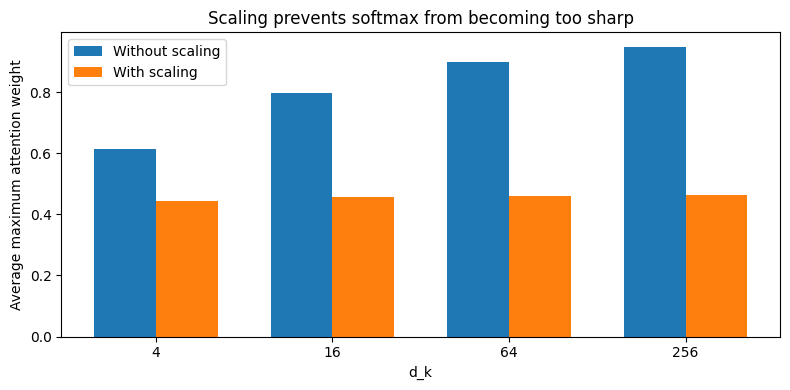

In [25]:
# Demonstrate why scaling matters

dimensions = [4, 16, 64, 256]
num_trials = 2000

avg_max_unscaled = []
avg_max_scaled = []

for d in dimensions:
    # Random queries and keys
    q = np.random.randn(num_trials, d)
    keys = np.random.randn(num_trials, 5, d)  # 5 keys for each query

    raw_scores = np.einsum("bd,bkd->bk", q, keys)
    scaled_scores = raw_scores / np.sqrt(d)

    w_raw = softmax(raw_scores, axis=-1)
    w_scaled = softmax(scaled_scores, axis=-1)

    avg_max_unscaled.append(w_raw.max(axis=-1).mean())
    avg_max_scaled.append(w_scaled.max(axis=-1).mean())

print("Average max attention weight without scaling:", np.round(avg_max_unscaled, 3))
print("Average max attention weight with scaling:   ", np.round(avg_max_scaled, 3))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(dimensions))
width = 0.35
ax.bar(x - width/2, avg_max_unscaled, width, label="Without scaling")
ax.bar(x + width/2, avg_max_scaled, width, label="With scaling")
ax.set_xticks(x)
ax.set_xticklabels(dimensions)
ax.set_xlabel("d_k")
ax.set_ylabel("Average maximum attention weight")
ax.set_title("Scaling prevents softmax from becoming too sharp")
ax.legend()
plt.tight_layout()
plt.show()

## Interpretation

Without scaling, the maximum attention weight tends to become larger as \(d_k\) increases.  
That means attention becomes more extreme.

With scaling by \(\sqrt{d_k}\), attention stays more balanced.

# 7. Positional encoding

Self-attention alone does **not** know word order.

The sentence:

```text
dog bites man
```

and

```text
man bites dog
```

contain the same words, but the meaning is different.

Transformers add position information to token embeddings.

The original Transformer used sinusoidal positional encoding:

$$
PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
$$

$$
PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
$$

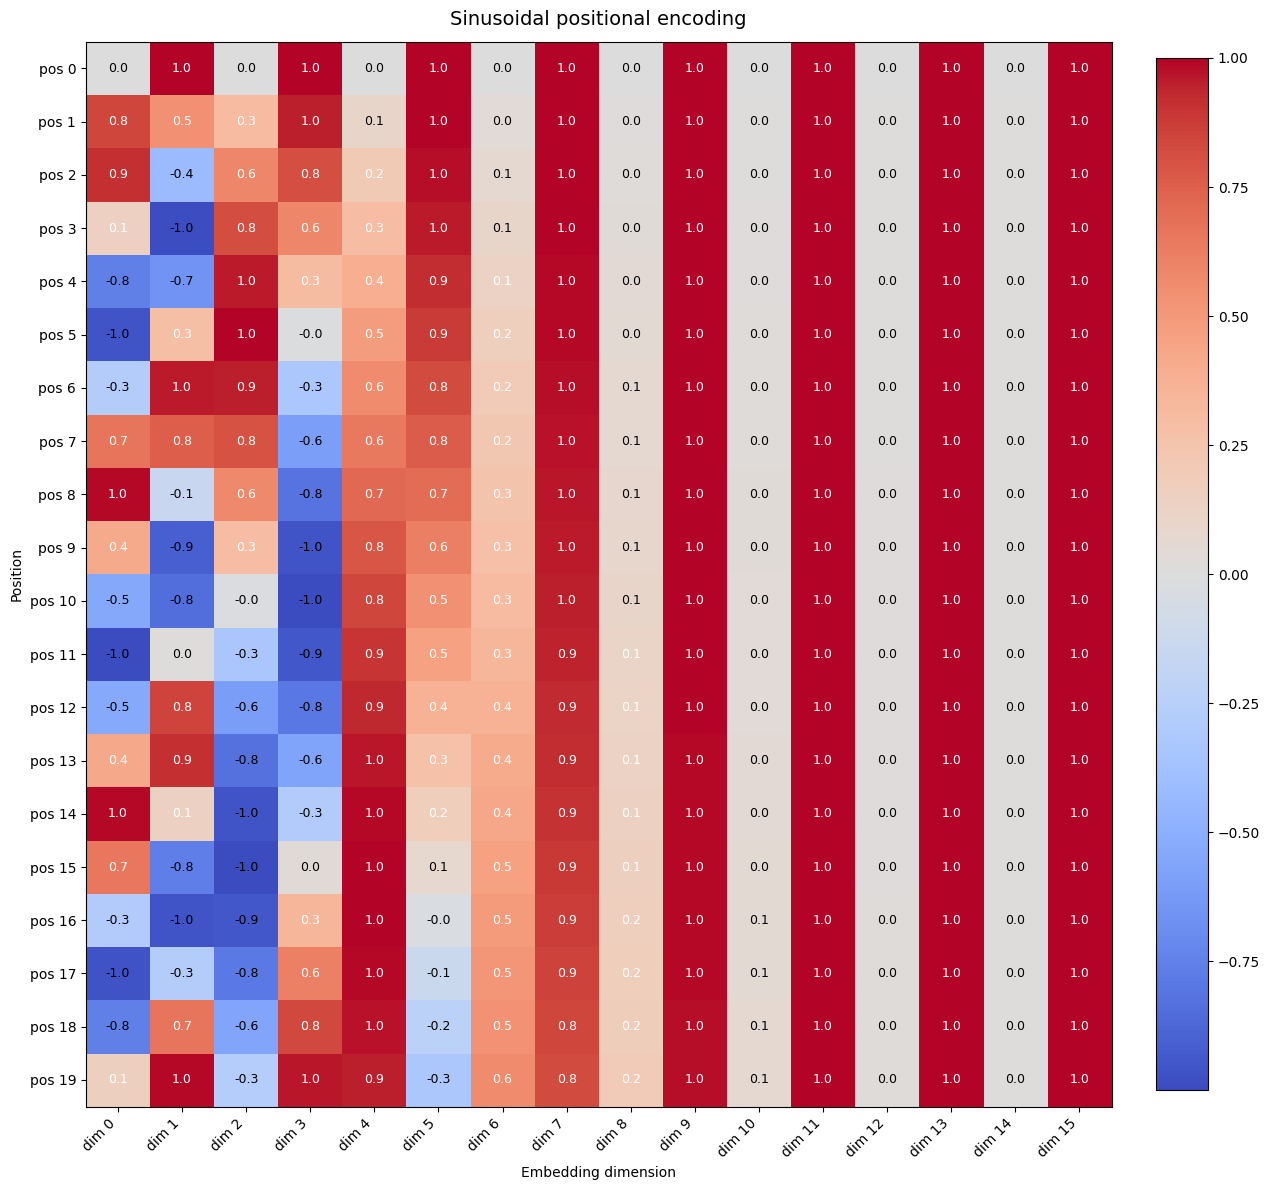

In [26]:
def positional_encoding(seq_len, d_model):
    pe = np.zeros((seq_len, d_model))
    positions = np.arange(seq_len)[:, np.newaxis]
    div_terms = np.exp(np.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
    pe[:, 0::2] = np.sin(positions * div_terms)
    pe[:, 1::2] = np.cos(positions * div_terms)
    return pe

seq_len = 20
d_model = 16
PE = positional_encoding(seq_len, d_model)

plot_heatmap(
    PE,
    x_labels=[f"dim {i}" for i in range(d_model)],
    y_labels=[f"pos {i}" for i in range(seq_len)],
    title="Sinusoidal positional encoding",
    xlabel="Embedding dimension",
    ylabel="Position",
    fmt=".1f",
    cmap="coolwarm"
)

## Order demonstration

Without positional encoding, the model mainly sees a collection of token embeddings.

Let us compare:

```text
dog bites man
man bites dog
```

The words are the same, but positions are different.

Sentence 1 embedding matrix:
['dog', 'bites', 'man']
[[1.  0.  0.2 0. ]
 [0.  1.  0.  0.1]
 [0.2 0.  1.  0. ]]

Sentence 2 embedding matrix:
['man', 'bites', 'dog']
[[0.2 0.  1.  0. ]
 [0.  1.  0.  0.1]
 [1.  0.  0.2 0. ]]


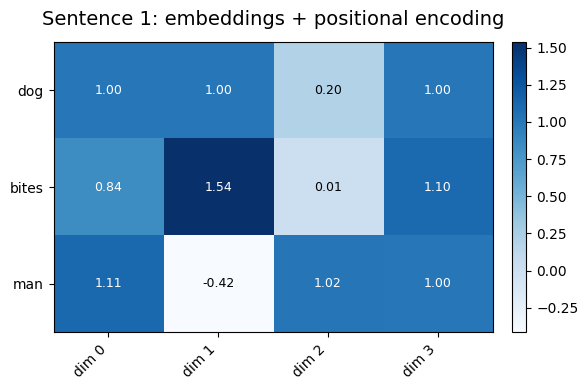

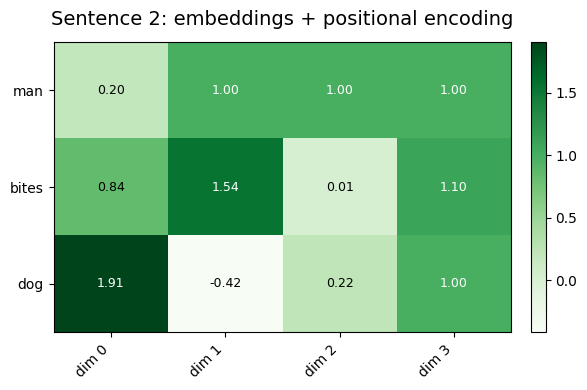

In [27]:
sent1 = ["dog", "bites", "man"]
sent2 = ["man", "bites", "dog"]

word_vectors = {
    "dog": np.array([1.0, 0.0, 0.2, 0.0]),
    "bites": np.array([0.0, 1.0, 0.0, 0.1]),
    "man": np.array([0.2, 0.0, 1.0, 0.0]),
}

X1 = np.vstack([word_vectors[w] for w in sent1])
X2 = np.vstack([word_vectors[w] for w in sent2])

# Same words, different order.
print("Sentence 1 embedding matrix:")
print(sent1)
print(X1)

print("\nSentence 2 embedding matrix:")
print(sent2)
print(X2)

# Add positional encoding
PE_small = positional_encoding(seq_len=3, d_model=4)
X1_pos = X1 + PE_small
X2_pos = X2 + PE_small

plot_heatmap(X1_pos, x_labels=[f"dim {i}" for i in range(4)], y_labels=sent1,
             title="Sentence 1: embeddings + positional encoding", cmap="Blues")
plot_heatmap(X2_pos, x_labels=[f"dim {i}" for i in range(4)], y_labels=sent2,
             title="Sentence 2: embeddings + positional encoding", cmap="Greens")

## Key idea

After adding positional encoding, the representation of a word depends on:

```text
word identity + word position
```

So "dog" at position 0 is represented differently from "dog" at position 2.



**Question:** Why does a Transformer need positional encoding?

** answer:**  
Because self-attention does not process tokens sequentially. Without positional information, it does not naturally know whether a word came first, second, or third.

### Two concepts students often mix up

- **Token embedding** answers: which token is this? (Learned from data.)
- **Position information** answers: where is it in the sequence? (Sinusoidal, learned, or relative/rotary variants.)
- **Self-attention** answers: which other token positions are relevant to update this representation?

Plain self-attention without position information is permutation-equivariant: reorder the input and its outputs reorder correspondingly; it has no built-in notion of first/last.

# 8. Causal masking in decoder self-attention

During text generation, the decoder predicts the next token using only previous tokens.

When predicting token 3, it should not look at token 4 or token 5.

This is why decoder self-attention uses a **causal mask**.

Example target sentence:

```text
we went to the market
```

When producing "to", the model may look at:

```text
we, went, to
```

but not:

```text
the, market
```

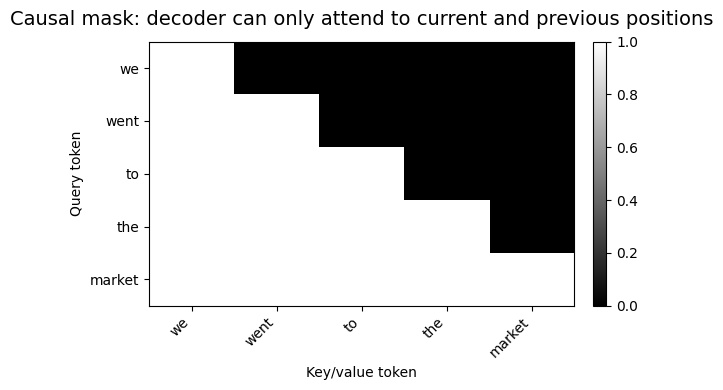

In [28]:
target_tokens = ["we", "went", "to", "the", "market"]
n = len(target_tokens)

# 1 means allowed, 0 means blocked
causal_mask = np.tril(np.ones((n, n)))

plot_heatmap(
    causal_mask,
    x_labels=target_tokens,
    y_labels=target_tokens,
    title="Causal mask: decoder can only attend to current and previous positions",
    xlabel="Key/value token",
    ylabel="Query token",
    fmt=".0f",
    cmap="gray"
)

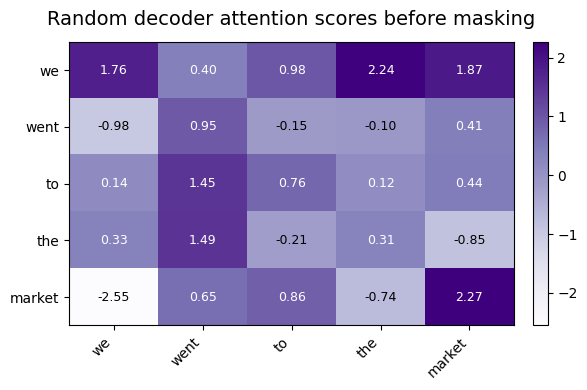

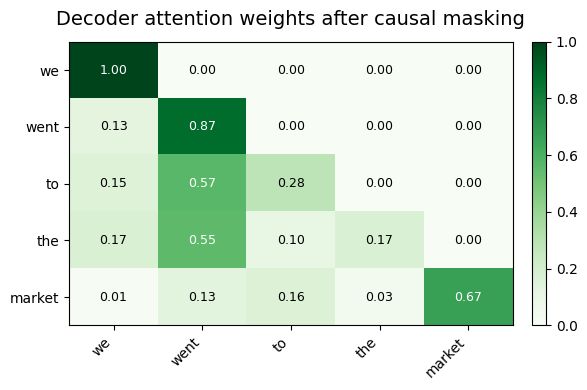

Rows still sum to 1 after masking:
[1. 1. 1. 1. 1.]


In [29]:
# Apply causal mask to attention scores

np.random.seed(0)
random_scores = np.random.randn(n, n)

# Mask future positions by setting them to a very negative number
masked_scores = np.where(causal_mask == 1, random_scores, -1e9)

unmasked_weights = softmax(random_scores, axis=-1)
masked_weights = softmax(masked_scores, axis=-1)

plot_heatmap(random_scores, x_labels=target_tokens, y_labels=target_tokens,
             title="Random decoder attention scores before masking", cmap="Purples")

plot_heatmap(masked_weights, x_labels=target_tokens, y_labels=target_tokens,
             title="Decoder attention weights after causal masking", cmap="Greens")

print("Rows still sum to 1 after masking:")
print(np.round(masked_weights.sum(axis=1), 3))

##

**Question:** Why does the decoder use causal masking?

** answer:**  
Because during generation, the model should not use future tokens. It must predict the next token using only tokens already generated.

### Encoder vs decoder: is masking always needed?

An encoder performing bidirectional understanding can usually view tokens on both sides. An autoregressive decoder generating the next token must **hide future positions**, otherwise training could leak the answer. Cross-attention in an encoder–decoder allows decoder queries to access encoder outputs.

Ask: when predicting the third token, should a decoder see token five? **No.**

# 9. Multi-head attention

One attention head may learn one type of relationship.

But language has many relationships:

- nearby words
- subject-verb relation
- pronoun reference
- adjective-noun relation
- verb-object relation
- long-range dependency

Multi-head attention lets the model attend in different ways at the same time.

Example sentence:

```text
the small dog chased the ball
```

We will create two hand-designed attention heads:

- **Head 1:** mostly local attention
- **Head 2:** relation-focused attention, e.g., "chased" attends to "dog" and "ball"

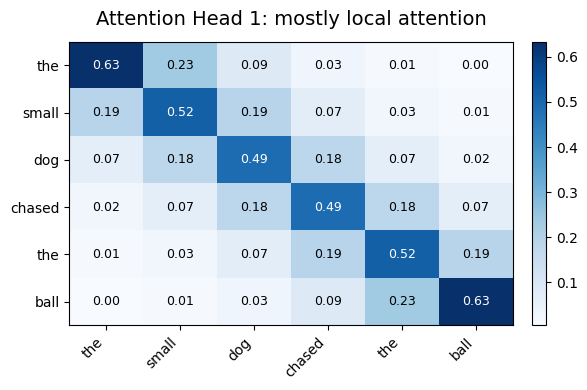

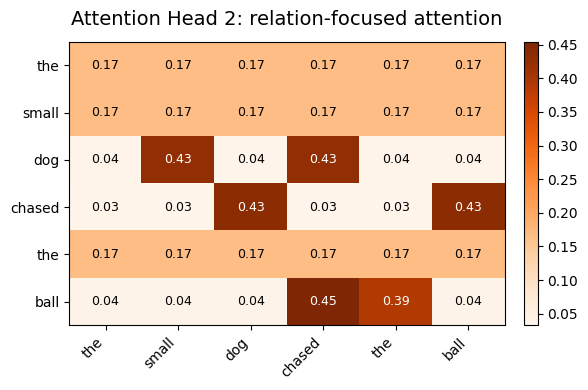

In [30]:
mh_tokens = ["the", "small", "dog", "chased", "the", "ball"]
m = len(mh_tokens)

# Head 1: local attention pattern
head1 = np.zeros((m, m))
for i in range(m):
    for j in range(m):
        head1[i, j] = np.exp(-abs(i-j))  # nearby tokens get higher score
head1 = head1 / head1.sum(axis=1, keepdims=True)

# Head 2: relation-focused attention pattern
head2 = np.ones((m, m)) * 0.03
# dog attends to small and chased
head2[2, 1] = 0.35
head2[2, 3] = 0.35
# chased attends to dog and ball
head2[3, 2] = 0.40
head2[3, 5] = 0.40
# ball attends to chased and the
head2[5, 3] = 0.35
head2[5, 4] = 0.30
# normalize rows
head2 = head2 / head2.sum(axis=1, keepdims=True)

plot_heatmap(head1, x_labels=mh_tokens, y_labels=mh_tokens,
             title="Attention Head 1: mostly local attention", cmap="Blues")

plot_heatmap(head2, x_labels=mh_tokens, y_labels=mh_tokens,
             title="Attention Head 2: relation-focused attention", cmap="Oranges")

## Checkpoint 6

**Question:** Why use multiple heads instead of one attention head?

**Expected answer:**  
Multiple heads allow the model to learn different types of relationships in parallel. One head may focus on nearby words, another on grammar, another on long-distance dependencies, and so on.

### Mini multi-head attention: the actual matrix operations

The two heatmaps above are **hand-designed** to demonstrate possible patterns. We now compute a small **real multi-head attention forward pass** (with *random, untrained* projection weights), so the Transformer block below is runnable.

For a sequence $X\in\mathbb{R}^{n\times d_{model}}$, choose $h$ heads so $d_h=d_{model}/h$. Per head we use:

$$Q_h=XW_{Q,h},\quad K_h=XW_{K,h},\quad V_h=XW_{V,h},\quad
A_h=\operatorname{softmax}(Q_hK_h^T/\sqrt{d_h}),\quad
Z_h=A_hV_h.$$

Concatenate $Z_1,\ldots,Z_h$ and use an output projection $W_O$. **This particular calculation shows the mechanism, not meaningful attention learned by training.**

X_8 (6, 8) multi-head output (6, 8)
weights per head: (2, 6, 6) = (heads, query tokens, key tokens)
Each attention row sums to 1: [[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]


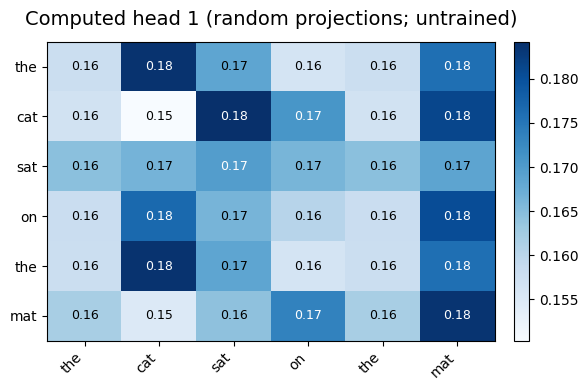

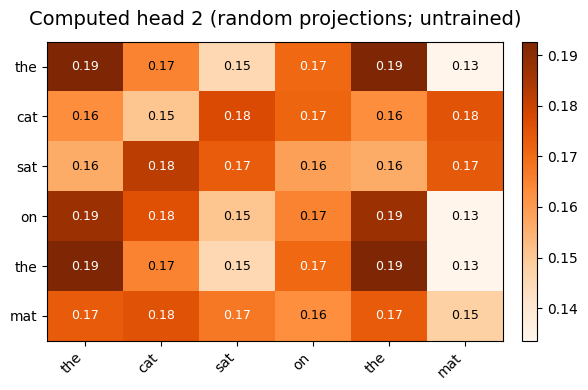

In [31]:
# X was defined earlier from the six-token sentence 'the cat sat on the mat'.
# Expand four toy features to eight so two heads each have width 4.
X_8 = np.concatenate([X, 0.5*X], axis=1)  # (6 tokens × 8 dimensions)

def multi_head_attention_numpy(X, num_heads=2, seed=1):
    """A minimal (untrained) multi-head self-attention forward pass."""
    n, d_model = X.shape
    assert d_model % num_heads == 0
    d_head = d_model // num_heads
    rng = np.random.default_rng(seed)
    std = 1.0 / np.sqrt(d_model)
    Wq, Wk, Wv, Wo = [rng.normal(0, std, size=(d_model,d_model)) for _ in range(4)]
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    # (n, model width) -> (heads, n, head width)
    heads = lambda T: T.reshape(n,num_heads,d_head).transpose(1,0,2)
    Qh, Kh, Vh = heads(Q), heads(K), heads(V)
    weights = softmax((Qh @ Kh.transpose(0,2,1)) / np.sqrt(d_head), axis=-1)
    Zh = weights @ Vh
    concatenated = Zh.transpose(1,0,2).reshape(n,d_model)
    out = concatenated @ Wo
    return out, weights

multihead_output, multihead_weights = multi_head_attention_numpy(X_8,num_heads=2,seed=1)
print("X_8", X_8.shape, "multi-head output", multihead_output.shape)
print("weights per head:", multihead_weights.shape, "= (heads, query tokens, key tokens)")
print("Each attention row sums to 1:", np.round(multihead_weights.sum(axis=-1), 5))
plot_heatmap(multihead_weights[0],x_labels=tokens,y_labels=tokens,
             title="Computed head 1 (random projections; untrained)",cmap="Blues")
plot_heatmap(multihead_weights[1],x_labels=tokens,y_labels=tokens,
             title="Computed head 2 (random projections; untrained)",cmap="Oranges")

# 10. Feed-forward network inside a Transformer

After attention, each token representation goes through a feed-forward network.

Usually, the FFN is applied independently to each token:

\[
\text{FFN}(x) = W_2 \sigma(W_1x + b_1) + b_2
\]

The usual dimension pattern is:

```text
d_model → d_ff → d_model
```

The output dimension returns to \(d_{model}\) because residual connections require the input and output shapes to match.

In [32]:
def relu(x):
    return np.maximum(0, x)

def feed_forward_network(X, d_ff=16, seed=0):
    """
    X shape: (seq_len, d_model)
    Returns shape: (seq_len, d_model)
    """
    np.random.seed(seed)
    seq_len, d_model = X.shape

    W1 = np.random.randn(d_model, d_ff) * 0.2
    b1 = np.zeros(d_ff)

    W2 = np.random.randn(d_ff, d_model) * 0.2
    b2 = np.zeros(d_model)

    hidden = relu(X @ W1 + b1)
    output = hidden @ W2 + b2
    return output, hidden

ffn_output, ffn_hidden = feed_forward_network(X_8, d_ff=16)

print("Input shape:", X_8.shape)
print("FFN hidden shape:", ffn_hidden.shape)
print("FFN output shape:", ffn_output.shape)

Input shape: (6, 8)
FFN hidden shape: (6, 16)
FFN output shape: (6, 8)


# 11. Residual connections and layer normalization

A Transformer block usually contains:

```text
Input
  ↓
Multi-head self-attention
  ↓
Add & Norm
  ↓
Feed-forward network
  ↓
Add & Norm
  ↓
Output
```

The "Add" part means residual connection:

\[
x + \text{sublayer}(x)
\]

Residual connections help gradients flow and make deep networks easier to train.

Input shape: (6, 8)
Transformer block output shape: (6, 8)


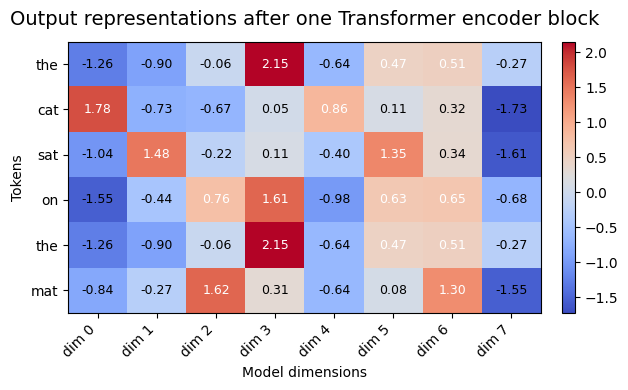

In [33]:
def layer_norm(X, eps=1e-6):
    """
    Simple layer normalization over the last dimension.
    X shape: (seq_len, d_model)
    """
    mean = X.mean(axis=-1, keepdims=True)
    var = X.var(axis=-1, keepdims=True)
    return (X - mean) / np.sqrt(var + eps)

def transformer_encoder_block_numpy(X, num_heads=2, d_ff=16, seed=1):
    """
    A minimal Transformer encoder block:
    Multi-head self-attention -> Add & Norm -> FFN -> Add & Norm
    """
    attn_out, attn_weights = multi_head_attention_numpy(X, num_heads=num_heads, seed=seed)
    x1 = layer_norm(X + attn_out)

    ffn_out, _ = feed_forward_network(x1, d_ff=d_ff, seed=seed+10)
    x2 = layer_norm(x1 + ffn_out)

    return x2, attn_weights

block_output, block_attention = transformer_encoder_block_numpy(X_8, num_heads=2, d_ff=16)

print("Input shape:", X_8.shape)
print("Transformer block output shape:", block_output.shape)

plot_heatmap(
    block_output,
    x_labels=[f"dim {i}" for i in range(block_output.shape[1])],
    y_labels=tokens,
    title="Output representations after one Transformer encoder block",
    xlabel="Model dimensions",
    ylabel="Tokens",
    cmap="coolwarm"
)

## Transformer encoder block summary

For each input token, the block produces a new contextual representation.

The representation contains:

1. the original token information,
2. information gathered from other tokens through self-attention,
3. transformed features from the feed-forward network.

## End-to-end mental model: a sentence travels through a Transformer

1. **Tokenize**: text → a sequence of token IDs.
2. **Embed**: IDs → $X$ (one vector per token).
3. **Supply positions**: make word order accessible to the model.
4. **Build Q, K, V**: learned linear maps from representations.
5. **Attention**: calculate relationships and mix value vectors.
6. **Multi-head**: repeat in distinct learned feature subspaces.
7. **Add & norm + FFN**: preserve and transform information per token.
8. **Repeat blocks**: stack layers to refine contextual representations.
9. **Use outputs**: for understanding, classification, or decoding tokens.

**Watch out:** a Transformer encoder by itself doesn't automatically generate next tokens; an appropriate decoder/language-model head and training objective are needed.

# 12. Encoder, decoder, and encoder-decoder attention

## Encoder block

Used in models like BERT.

```text
Input tokens
  ↓
Self-attention
  ↓
Feed-forward network
  ↓
Contextual token representations
```

The encoder can attend bidirectionally because it sees the whole input.

---

## Decoder block

Used in models like GPT.

```text
Previous output tokens
  ↓
Masked self-attention
  ↓
Feed-forward network
  ↓
Next-token prediction
```

The decoder uses causal masking so it cannot see future tokens.

---

## Encoder-decoder model

Used in the original Transformer for translation.

```text
Source sentence → Encoder
Target prefix → Decoder
Decoder also attends to encoder outputs using cross-attention
```

This is useful when input and output are different sequences, such as translation or summarization.

# 13. Student activity: trace one token

Let us trace the token **cat** in:

```text
the cat sat on the mat
```

Question:

> Which tokens does "cat" attend to, and how does that affect the final representation?

Attention weights for 'cat':
cat -> the: 0.149
cat -> cat: 0.241
cat -> sat: 0.161
cat ->  on: 0.148
cat -> the: 0.149
cat -> mat: 0.153


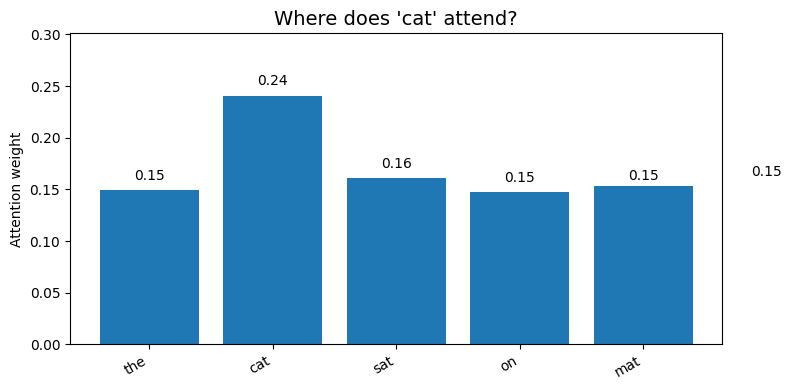


Context vector for 'cat':
[0.287 0.229 0.258 0.416]


In [34]:
query_token = "cat"
query_index = tokens.index(query_token)

cat_weights = self_attention_weights[query_index]

print(f"Attention weights for '{query_token}':")
for tok, w in zip(tokens, cat_weights):
    print(f"{query_token} -> {tok:>3}: {w:.3f}")

plot_bar(tokens, cat_weights, title=f"Where does '{query_token}' attend?", ylabel="Attention weight")

print("\nContext vector for 'cat':")
print(np.round(context_vectors[query_index], 3))

# Reading material

## Student activity answer

The context vector for **cat** is a weighted mixture of all value vectors.

If "cat" gives weight to "sat", its representation can include action information.  
If it gives weight to "mat", it can include location/object information.  
If it gives weight to "the", it may include function-word/context information.

## 14. Common confusions

## Confusion 1: Are Q, K, and V different words?

No. They are different **representations** created from token embeddings.

For self-attention:

```text
same input X → three projections → Q, K, V
```

## Confusion 2: Does high attention always mean causal importance?

Not always. Attention weights can be useful for inspection, but they are not a perfect explanation.

## Confusion 3: Why not just use RNNs?

RNNs process tokens sequentially. Transformers process tokens in parallel and use attention to connect tokens directly.

## Confusion 4: Why do we need positional encoding?

Because attention itself does not know order.

## Confusion 5: Why does decoder masking matter?

Without masking, the decoder could cheat during training by looking at future target tokens.

## 15. Practice questions with answers

## Q1. What is the role of softmax in attention?

**Answer:**  
Softmax converts raw similarity scores into attention weights. These weights are non-negative and sum to 1.

---

## Q2. What is the difference between self-attention and cross-attention?

**Answer:**  
In self-attention, Q, K, and V come from the same sequence.  
In cross-attention, Q comes from one sequence, while K and V come from another sequence.

Example:

- Decoder query attends to encoder keys and values in translation.

---

## Q3. Why is \(QK^T\) used?

**Answer:**  
It computes similarity between every query and every key. The result tells us how relevant each key/value token is to each query token.

---

## Q4. Why divide by \(\sqrt{d_k}\)?

**Answer:**  
To keep dot-product scores from becoming too large when vector dimension increases. This keeps softmax from becoming too sharp.

---

## Q5. What does multi-head attention add?

**Answer:**  
It allows the model to learn multiple attention patterns in parallel.

---

## Q6. Why does the FFN return to \(d_{model}\)?

**Answer:**  
Because Transformer blocks use residual connections, and residual addition requires matching dimensions.

---

## Q7. What is causal masking?

**Answer:**  
A mask that prevents a decoder token from attending to future tokens.

---

## Q8. Why do Transformers add positional encoding to embeddings?

**Answer:**  
Because self-attention does not naturally encode word order.

## Extra practice questions

1. Why are token IDs not meaningful numerical features?
2. What does an embedding table return given a token ID?
3. Why can static embeddings struggle with the word `bank`?
4. Why divide attention scores by $\sqrt{d_k}$?
5. How does causal attention differ from bidirectional attention?

<details><summary>Suggested answers</summary>

1. IDs are arbitrary categorical labels. 2. A learned dense vector. 3. Context changes meaning but static lookup doesn't. 4. It stabilizes score magnitude and softmax sharpness under typical assumptions. 5. Causal disallows looking ahead; bidirectional typically allows all positions (subject to padding masks).

</details>

**Optional challenge:** Swap the first and last tokens; explain why *positional information* is needed. Then change the values $V$ while keeping $Q,K$ fixed: do attention **weights** change, or just the **output**? (Only the output changes.)

## 16. Final cheat sheet

## Attention formula

\[
\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

## Meaning of Q, K, V

| Symbol | Meaning |
|---|---|
| Q | What the token is looking for |
| K | What each token offers for matching |
| V | The information each token provides |

## Self-attention

```text
Q, K, V all come from the same sequence
```

## Cross-attention

```text
Q comes from decoder
K and V come from encoder
```

## Decoder masked attention

```text
future tokens are blocked
```

## Transformer encoder block

```text
Input
 → Multi-head self-attention
 → Add & Norm
 → Feed-forward network
 → Add & Norm
 → Output
```

## Transformer decoder block

```text
Input
 → Masked self-attention
 → Add & Norm
 → Cross-attention
 → Add & Norm
 → Feed-forward network
 → Add & Norm
 → Output
```

---

# End of notebook

You can now explain attention, self-attention, positional encoding, masking, multi-head attention, and the basic Transformer block.

## Text-to-vector summary

- **Token ID $i$:** integer row address (not a semantic value).
- **One-hot $h_i$:** a sparse $1\times V$ representation of identity.
- **Embedding $e_i=h_i E=E[i,:]$:** a short **trainable** $1\times d$ vector.
- **Why embeddings learn:** prediction **loss → gradients → updated embedding rows**.
- **Contextual representation:** a Transformer uses attention to turn base vectors into sentence-dependent representations.


## Further visual reading:
https://magazine.sebastianraschka.com/p/visual-attention-variants